In [2]:
import re
import torch
import numpy as np
import pandas as pd
import string
from scipy.stats import rankdata

def preproc_method_name(x):
    return x

def get_table_short(path, metric_names=['AlignScore'], dataset="CoQA", ue_metric="prr_0.5_normalized", level="sequence"):
    
    df = {}

    if isinstance(path, list):
        for i, p in enumerate(path):
            man = torch.load(p, weights_only=False)
            methods = np.unique([x[1] for x in man['metrics'].keys() if "2side" not in x[1]])

            for method in methods:
                if method in df and i > 0:
                    continue
                for metric in metric_names:
                    key = (level, method, metric, ue_metric)
                    scores = df.get(method, [])
                    scores.append(man['metrics'][key])
                    df[method] = scores
    else:
        man = torch.load(path, weights_only=False)
        methods = np.unique([x[1] for x in man['metrics'].keys() if "2side" not in x[1]])

        for method in methods:
            for metric in metric_names:
                key = (level, method, metric, ue_metric)
                scores = df.get(method, [])
                scores.append(man['metrics'][key])
                df[method] = scores

    df0 = pd.DataFrame(df, index=pd.MultiIndex.from_tuples([(dataset, m) for m in metric_names])).T
    df0.loc[:, (dataset, 'Method')] = [x for x in df0.index]
    return df0.reset_index(drop=True)

# LLaDa-1.5

In [6]:
import os
import copy
from scipy.stats import rankdata

base_path = "./workdir/output_dllm_dec25_maskedll_final"

datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        # "SamSum": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-25/01-04-55/ue_manager_seed1",
        # "XSUM": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-03-25/16-52-38/ue_manager_seed1",
        # "WMT14": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-25/04-09-53/ue_manager_seed1",
        # "WMT19": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-25/08-14-48/ue_manager_seed1",
        # "CoQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-10/21-58-20/ue_manager_seed1",
        # "GSM8k": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-03-24/14-28-05/ue_manager_seed1",
        # "MMLU": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-03-25/15-16-53/ue_manager_seed1",
        # "TriviaQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-11/00-58-13/ue_manager_seed1",

        # "TruthfulQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-11/03-32-27/ue_manager_seed1",

        # "SamSum": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1",
        # "GSM8k": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-19/15-37-54/ue_manager_seed1",
        # "CoQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-27/14-18-55/ue_manager_seed1",
        # "TriviaQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-27/19-07-35/ue_manager_seed1",
        # "MMLU": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-27/17-29-11/ue_manager_seed1",
        # "WMT14": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1",
        # "WMT19": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-27/21-24-12/ue_manager_seed1",
        # "XSUM": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1",    

        # "SamSum": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1",
        # "GSM8k": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-29/02-02-10/ue_manager_seed1",
        # "CoQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-28/22-17-01/ue_manager_seed1",
        # "TriviaQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-29/00-32-16/ue_manager_seed1",
        # "MMLU": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-28/23-42-57/ue_manager_seed1",
        # "WMT14": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1",
        # "WMT19": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-29/10-37-01/ue_manager_seed1",
        # "XSUM": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1",   

        "SamSum": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"
        ],
        "GSM8k": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-19/15-37-54/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-29/02-02-10/ue_manager_seed1"
        ],
        "CoQA": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-27/14-18-55/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-28/22-17-01/ue_manager_seed1"
        ],
        "TriviaQA": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-27/19-07-35/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-29/00-32-16/ue_manager_seed1"
        ],
        "MMLU": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-27/17-29-11/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-28/23-42-57/ue_manager_seed1"
        ],
        "WMT14": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"
        ],
        "WMT19": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-27/21-24-12/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-29/10-37-01/ue_manager_seed1"
        ],
        "XSUM": [
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1",
            "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"
        ],
 
    }
}

filename = "ue_manager_seed1"
dfs = {}

all_paths = []
for model in models:
    dfs[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        task = ds.split("/")[0]
        ds = '/'.join(ds.split("/")[1:])
        path = f"{base_path}/{task}/{model}/{ds}/"
        final_path = None
        if model in paths.keys() and ds_name in paths[model].keys():
            final_path = paths[model][ds_name]
        else:
            continue
        if final_path is not None:
            print(final_path)
            all_paths.append(final_path)
            if task == "ats":
                metric_names=['AlignScore']
            elif (ds_name in ["MMLU", "GSM8k"]):
                metric_names=["Accuracy"]
            elif task == "qa":
                metric_names=['AlignScore']
            elif task == "nmt":
                metric_names=['Comet']
            df = get_table_short(final_path, dataset=ds_name, metric_names=metric_names)
            dfs[model][ds_name] = df.reset_index(drop=True)

["/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1", "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"]
["/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1", "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"]
["/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_

In [7]:
dfs_short_new = []
methods = None
model = models[0]

for key in dfs[model].keys():
    df_ = dfs[model][key]   
    if methods is None:
        methods = df_[df_.columns[-1]]
        # methods = [m for m in methods if "CocoaMCMaskedNLL" in m]
        # methods = [m for m in methods if "DebertaContra" not in m]
        # methods = [m for m in methods if "InverseProgress" not in m]
        # methods = [m for m in methods if "BlockMax" not in m]
    df_ = df_.set_index(df_.columns[-1], drop=False).reindex(methods)
    
    if len(dfs_short_new):
        dfs_short_new.append(df_[df_.columns[[0]]])
    else:
        dfs_short_new.append(df_[df_.columns[[1, 0]]])
dfs_short_new = pd.concat(dfs_short_new, axis=1).reset_index(drop=True)
# dfs_short_new.loc[:, ('', "Mean")] = dfs_short_new[dfs_short_new.columns[1:]].mean(axis=1)
# dfs_short_new.loc[:, ('', "Mean Rank")] = dfs_short_new[dfs_short_new.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [8]:
# dfs_short_new.sort_values(dfs_short_new.columns[-2], ascending=False).style.background_gradient(axis=0)

In [9]:
paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "SamSum": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
        "WMT14": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1",
        "WMT19": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1",
        "TriviaQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1",
        "CoQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1",
        # "TruthfulQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-07/06-40-05/ue_manager_seed1",
        "MMLU": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1",
        "XSUM": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1",
        "GSM8k": ["/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-31/ue_manager_seed1",
                  "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-29/ue_manager_seed1"],
    }
}


filename = "ue_manager_seed1"
dfs = {}

all_paths = []
for model in models:
    dfs[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        task = ds.split("/")[0]
        ds = '/'.join(ds.split("/")[1:])
        path = f"{base_path}/{task}/{model}/{ds}/"
        final_path = None
        if model in paths.keys() and ds_name in paths[model].keys():
            final_path = paths[model][ds_name]
        else:
            continue
        if final_path is not None:
            print(final_path)
            all_paths.append(final_path)
            if task == "ats":
                metric_names=['AlignScore']
            elif (ds_name in ["MMLU", "GSM8k"]):
                metric_names=["Accuracy"]
            elif task == "qa":
                metric_names=['AlignScore']
            elif task == "nmt":
                metric_names=['Comet']
            df = get_table_short(final_path, dataset=ds_name, metric_names=metric_names)
            dfs[model][ds_name] = df.reset_index(drop=True)

/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.

In [10]:
dfs_short = []
methods = None
model = models[0]

for key in dfs[model].keys():
    df_ = dfs[model][key]   
    if methods is None:
        methods = df_[df_.columns[-1]]
        # methods = [m for m in methods if "FullTrace" in m]
        # methods = [m for m in methods if "InverseProgress" not in m]
    df_ = df_.set_index(df_.columns[-1], drop=False).reindex(methods)
    
    if len(dfs_short):
        dfs_short.append(df_[df_.columns[[0]]])
    else:
        dfs_short.append(df_[df_.columns[[1, 0]]])
dfs_short = pd.concat(dfs_short, axis=1).reset_index(drop=True)
# dfs_short.loc[:, ('', "Mean")] = dfs_short[dfs_short.columns[1:]].mean(axis=1)
# dfs_short.loc[:, ('', "Mean Rank")] = dfs_short[dfs_short.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [11]:
paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "TriviaQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-07-16/07-29-41/ue_manager_seed1",
        "SamSum": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-07-17/05-31-33/ue_manager_seed1",
        "CoQA": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-07-16/23-17-54/ue_manager_seed1",
        "WMT14": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-07-16/18-00-04/ue_manager_seed1",
        "WMT19": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-07-17/01-09-08/ue_manager_seed1",
        "GSM8k": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-07-17/04-44-19/ue_manager_seed1",
        "MMLU": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-07-16/20-42-41/ue_manager_seed1",
        "XSUM": "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-07-17/13-36-05/ue_manager_seed1"
    },
}


filename = "ue_manager_seed1"
dfs = {}

all_paths = []
for model in models:
    dfs[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        task = ds.split("/")[0]
        ds = '/'.join(ds.split("/")[1:])
        path = f"{base_path}/{task}/{model}/{ds}/"
        final_path = None
        if model in paths.keys() and ds_name in paths[model].keys():
            final_path = paths[model][ds_name]
        else:
            continue
        if final_path is not None:
            print(final_path)
            all_paths.append(final_path)
            if task == "ats":
                metric_names=['AlignScore']
            elif (ds_name in ["MMLU", "GSM8k"]):
                metric_names=["Accuracy"]
            elif task == "qa":
                metric_names=['AlignScore']
            elif task == "nmt":
                metric_names=['Comet']
            df = get_table_short(final_path, dataset=ds_name, metric_names=metric_names)
            dfs[model][ds_name] = df.reset_index(drop=True)

/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-07-17/13-36-05/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-07-17/05-31-33/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-07-16/18-00-04/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-07-17/01-09-08/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-07-16/23-17-54/ue_manager_seed1
/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/output_llada_new/qa/GSAI

In [12]:
dfs_short_new_2 = []
methods = None
model = models[0]

for key in dfs[model].keys():
    df_ = dfs[model][key]   
    if methods is None:
        methods = df_[df_.columns[-1]]
        # methods = [m for m in methods if "FullTrace" in m]
        # methods = [m for m in methods if "InverseProgress" not in m]
    df_ = df_.set_index(df_.columns[-1], drop=False).reindex(methods)
    
    if len(dfs_short_new_2):
        dfs_short_new_2.append(df_[df_.columns[[0]]])
    else:
        dfs_short_new_2.append(df_[df_.columns[[1, 0]]])
dfs_short_new_2 = pd.concat(dfs_short_new_2, axis=1).reset_index(drop=True)
# dfs_short_new_2.loc[:, ('', "Mean")] = dfs_short_new_2[dfs_short_new_2.columns[1:]].mean(axis=1)
# dfs_short_new_2.loc[:, ('', "Mean Rank")] = dfs_short_new_2[dfs_short_new_2.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [13]:
df_all = pd.concat([dfs_short, dfs_short_new, dfs_short_new_2], axis=0).reset_index(drop=True)
df_all.loc[:, ('', "Mean")] = df_all[df_all.columns[1:]].mean(axis=1)
# df_all.loc[:, ('', "Mean Rank")] = df_all[df_all.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [78]:
from lm_polygraph.ue_metrics.pred_rej_area import PredictionRejectionArea
from lm_polygraph.ue_metrics.ue_metric import get_random_scores

prr = PredictionRejectionArea(0.5)

gen_ppl_path = "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/genppl_per_example.csv"
df_gen_ppl = pd.read_csv(gen_ppl_path)
scores = {"Method": ["Gen PPL"]}
for datasets in ['XSUM', 'SamSum', "WMT14", "WMT19", 'CoQA', "TriviaQA", "MMLU", "GSM8k"]:
    df_ds = df_gen_ppl.loc[df_gen_ppl['dataset'] == datasets]
    ue = -np.array(df_ds['gen_ppl'].values)
    if (datasets in ["MMLU", "GSM8k"]):
        metrics = np.array(df_ds['accuracy'].values)
    elif (datasets in ["WMT14", "WMT14"]):
        metrics = np.array(df_ds['comet'].values)
    else:
        metrics = np.array(df_ds['alignscore'].values)

    mean_val = prr(ue, metrics) 
    oracle = prr(-metrics, metrics)
    random = get_random_scores(prr, metrics)
    scores[datasets] = [(mean_val - random) / (oracle - random)]

In [83]:
genppl_scores = pd.DataFrame(scores)
genppl_scores["Mean"] = genppl_scores[genppl_scores.columns[1:]].mean(axis=1)

In [81]:
df_all_selected_ = df_all.iloc[[589]]
genppl_scores.columns = df_all_selected_.columns
df_all_selected_ = pd.concat([genppl_scores, df_all_selected_], axis=0).reset_index(drop=True)
df_all_selected_[df_all_selected_.columns[0]] = df_all_selected_[df_all_selected_.columns[0]].replace({"MaximumSequenceProbability": "MSP", "ConfidenceAtCommit_avg": "CommitNLL", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G", "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCNLL-Norm", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L"})
df_all_selected_.style.background_gradient(axis=0)

In [89]:
print(df_all_selected_.round(2).to_markdown(index=False).strip())

| ('XSUM', 'Method')   |   ('XSUM', 'AlignScore') |   ('SamSum', 'AlignScore') |   ('WMT14', 'Comet') |   ('WMT19', 'Comet') |   ('CoQA', 'AlignScore') |   ('TriviaQA', 'AlignScore') |   ('MMLU', 'Accuracy') |   ('GSM8k', 'Accuracy') |   ('', 'Mean') |
|:---------------------|-------------------------:|---------------------------:|---------------------:|---------------------:|-------------------------:|-----------------------------:|-----------------------:|------------------------:|---------------:|
| Gen PPL              |                     0.02 |                       0.08 |                -0.29 |                -0.14 |                    -0.03 |                        -0.08 |                  -0.03 |                    0.09 |          -0.05 |
| D-CoCoA-L            |                     0.22 |                       0.23 |                 0.41 |                 0.48 |                     0.28 |                         0.53 |                   0.46 |                    0.23 |      

In [12]:
# df_all.iloc[[589, 593, 594, 595, 591, 235, 145]].sort_values(df_all.columns[-1], ascending=False).style.background_gradient(axis=0)

In [13]:
df_all.sort_values(df_all.columns[-1], ascending=False).style.background_gradient(axis=0) #CocoaMCMaskedNLLCrossEncoderFullTraceNFE

In [21]:
np.unique(df_all[df_all.columns[0]].to_list()).shape

(605,)

In [279]:
import matplotlib 
from matplotlib import colors
import matplotlib.pyplot as plt 

cmap = matplotlib.cm.get_cmap('coolwarm_r')#'Greens')
my_cmap = cmap(np.arange(cmap.N))
my_cmap[:,-1] = 0.5
my_cmap = colors.ListedColormap(my_cmap)

def b_g(s, cmap, low=0, high=0):
    values = s.apply(lambda x: float(x.split("±")[0]) if len(x.split("±"))>1 else x)
    if isinstance(values.max(), str):
        return ['' for c in values]
    rng = values.max() - values.min()
    norm = colors.Normalize(values.min() - (rng * low), values.max() + (rng * high))
    normed = norm(values.values)
    back_colors = [colors.rgb2hex(x) for x in plt.cm.get_cmap(cmap)(normed)]
    text_colors = ["white" if x>0.3 else "black" for x in normed]
    return [f'color: {text_color}; background-color: {color}' for text_color, color in zip(text_colors, back_colors)]

def rgba2rgb(rgba, background=(1,1,1)):
    ch = rgba.shape[0]
    if ch == 3:
        return rgba

    assert ch == 4, 'RGBA image has 4 channels.'

    r, g, b, a = rgba[0], rgba[1], rgba[2], rgba[3]
    a = np.asarray(a, dtype='float32')
    R, G, B = background

    r_new = r * a + (1.0 - a) * R
    g_new = g * a + (1.0 - a) * G
    b_new = b * a + (1.0 - a) * B

    return [r_new, g_new, b_new]


def to_color(text, vals):
    vals = rgba2rgb(np.array(vals))
    return '\\cellcolor[rgb]{'+f'{vals[0]},'+f'{vals[1]},'+f'{vals[2]}'+'} '+f'{text:.2f}'

def bold_best(df, columns):
    for col in columns:
        values_init_raw = [float(x) if x!='-' else np.nan for x in df[col]]
        values_init = np.array([float(x) for x in df[col] if x!='-'])
        if values_init.min() != values_init.max():
            values_init_raw = np.array([(x - values_init.min()) / (values_init.max() - values_init.min()) if not np.isnan(x) else x for x in values_init_raw])
            
        def get_new_x(x):
            if isinstance(x, str):
                return x
            return '-'
        values = [to_color(raw, my_cmap(1-float(x))) if (isinstance(x, float) and (not np.isnan(x))) else get_new_x(x) for raw, x in zip(df[col], values_init_raw)]
        df[col] = values
    return df

def prepare_latex(df1, s=2):
    start_tex = '\\begin{table*}[!ht] \\resizebox{\\textwidth}{!}{'
    end_tex = "}\\caption{\\label{tab:mistral_results} PRR$\\uparrow$ for Mistral 7b v0.2 model for various tasks for the considered sequence-level methods. Darker color indicates better results.}\end{table*}"
    df1 = bold_best(df1, df1.columns[s:])
    latex_table = df1.to_latex(bold_rows=False, index=False).replace('±', '$\pm$')
        
    latex_table = latex_table.replace('\\textbackslash ', '\\')
    latex_table = latex_table.replace('{lllllllllllllllllllll}', '{ll||cc|cc|cc|cc|cc|cc|cc|cc|cc|c}')
    latex_table = latex_table.replace('{llllllllllllllllllll}', '{l||cc|cc|cc|cc|cc|cc|cc|cc|cc|c}')
    latex_table = latex_table.replace('{lllllllllllllll}', '{ll||cc|cc|cc|cc|cc|cc|c}')
    latex_table = latex_table.replace('{lllllllll}', '{ll||cc|cc|cc|c}')
    latex_table = latex_table.replace('{llllllll}', '{l|c|c|c|c|c|c|c}')
    latex_table = latex_table.replace('{llllllllll}', '{l|c|c|c|c|c|c|c|c|c}')

    
    latex_table = latex_table.replace('mean', '$\\frac{1}{K}\\sum_{k=1}^K p_k$')
    latex_table = latex_table.replace('sum(log(p_i))', '$\\sum_{k=1}^K \\log p_k$')

    latex_table = latex_table.replace('\\{', '{')
    latex_table = latex_table.replace('\\}', '}')
    str_list = latex_table.split('\n')
    str_list.pop(3)
    latex_table = '\n'.join(str_list)
    return start_tex+latex_table+end_tex

/tmp/ipykernel_1589770/3824649416.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = matplotlib.cm.get_cmap('coolwarm_r')#'Greens')


### Results with baseline

In [280]:
df_all_selected = df_all.iloc[[47,
                               68, 7,
                               30,
                               77,
                               564, 569, 118, 537, 4, 5,
                               235, 589]]
df_all_selected[df_all_selected.columns[0]] = df_all_selected[df_all_selected.columns[0]].replace({"MaximumSequenceProbability": "MSP", "ConfidenceAtCommit_avg": "CommitNLL", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G", "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCNLL-Norm", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L"})
df_all_selected.style.background_gradient(axis=0)

In [281]:
# df_all_selected = df_all.iloc[[548,
#                                68, 7,
#                                32, 30,
#                                77,
#                                546, 554, 549, 4, 115, 230,]]
# df_all_selected[df_all_selected.columns[0]] = df_all_selected[df_all_selected.columns[0]].replace({"MaximumSequenceProbability": "MSP", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-NFE", "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ"})
# df_all_selected.style.background_gradient(axis=0)

In [282]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_all_selected).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MSP & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.08 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.11 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.20 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.16 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.02 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.05 & \cellcolor[rgb]{0.9791396989627451,0.8021675484411765,0.7416485506941177} 0.34 & \cellcolor[rgb]{0.7311771982901961,0.7999150558117647,0.9829285958960784} 0.09 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.10 \\
SAR & \cellcolor[rgb]{0.9236824528058825,0.9312362411882353,0.9427702351823529} 0.07 & \cel

In [283]:
df_baselines_ar = df_all.iloc[[47, 50, 61, 0, 2, 62,
                               51, 73, 68, 27, 7, 71,
                               32, 30, 14, 
                               67, 69, 42, 77]]
df_baselines_ar[df_baselines_ar.columns[0]] = df_baselines_ar[df_baselines_ar.columns[0]].replace(
    {"MaximumSequenceProbability": "MSP", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCMaskedNLL", 
     "TraceEntropy_avg": "TraceEntropy", "AvgDissimilarityFullTrace": "AvgDissim", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "CoCoA-NFE", 
     "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCMaskedNormNLL", "TAD": "TAD", "SAR": "SAR", 
     "SAPLMA_decoder_16": "SAPLMA", "SATRMD_decoder": "SATRMD", "MonteCarloNormalizedSequenceEntropy": "MCNSE", "AttentionScore (layer=16)": "AttScore", "MeanTokenEntropy": "MTE",
     "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ"})
df_baselines_ar.style.background_gradient(axis=0)

In [284]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_ar).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MSP & \cellcolor[rgb]{0.6449978024117646,0.6934178380941176,0.9144631795921568} -0.08 & \cellcolor[rgb]{0.8910245585529412,0.9214321063294117,0.9714899216352941} 0.11 & \cellcolor[rgb]{0.7825907906117646,0.8497192224705883,0.9983175350588236} 0.20 & \cellcolor[rgb]{0.7635661295607843,0.8323498010588236,0.9945323233411765} 0.16 & \cellcolor[rgb]{0.6309026780784314,0.6732421581529412,0.8978288875588235} -0.02 & \cellcolor[rgb]{0.6449978024117646,0.6934178380941176,0.9144631795921568} 0.05 & \cellcolor[rgb]{0.9720272867117647,0.7765767393745098,0.7177742451568627} 0.34 & \cellcolor[rgb]{0.6892991246352941,0.7519281085960785,0.9568458054235294} 0.09 & \cellcolor[rgb]{0.6355521478235294,0.6800053309882352,0.903547563717

In [285]:
df_baselines_diff = df_all.iloc[[564, 565, 569, 579, 79, 587, 583, 537]]
df_baselines_diff[df_baselines_diff.columns[0]] = df_baselines_diff[df_baselines_diff.columns[0]].replace(
    {"MaximumSequenceProbability": "MSP", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceProbs_avg": "TrajProbs", "RemaskCountMean": "Remask", 
     "ArgmaxFlipCount_avg": "FlipCount", "MCMaskedNormalizedNLL": "MCNLL-Norm",
     "ConfidenceAtCommit_avg": "CommitNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AvgDissim", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "CoCoA-NFE", 
     "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCMaskedNormNLL", "TAD": "TAD", "SAR": "SAR", 
     "SAPLMA_decoder_16": "SAPLMA", "SATRMD_decoder": "SATRMD", "MonteCarloNormalizedSequenceEntropy": "MCNSE", "AttentionScore (layer=16)": "AttScore", "MeanTokenEntropy": "MTE",
     "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ"})
df_baselines_diff.style.background_gradient(axis=0)

In [286]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_diff).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MCNLL & \cellcolor[rgb]{0.9841016995,0.8604220499999999,0.8061464956666666} 0.17 & \cellcolor[rgb]{0.9591408362921569,0.742086736090196,0.6888969625352941} 0.18 & \cellcolor[rgb]{0.931695915645098,0.9325418979098039,0.9338169421313726} 0.29 & \cellcolor[rgb]{0.953077067017647,0.9210455325882353,0.9030752965411765} 0.32 & \cellcolor[rgb]{0.931695915645098,0.9325418979098039,0.9338169421313726} 0.24 & \cellcolor[rgb]{0.9824176791176471,0.8723068372941176,0.8216194376764705} 0.31 & \cellcolor[rgb]{0.9813503623666666,0.8141088755,0.7538180498} 0.35 & \cellcolor[rgb]{0.9720272867117647,0.7765767393745098,0.7177742451568627} 0.23 & \cellcolor[rgb]{0.9704394715,0.9027982014117647,0.8675832782352941} 0.26 \\
MCNLL-Norm & \

In [287]:
df_baselines_traj = df_all.iloc[[82, 84, 118, 120, 121, 123, 124, 126]]
df_baselines_traj[df_baselines_traj.columns[0]] = df_baselines_traj[df_baselines_traj.columns[0]].replace(
    {"AvgDissimilarityBlockAvgTrace": "AD-Block",
     "AvgDissimilarityBlockAvgTraceProgress": "WeightedAD-Block",
     "AvgDissimilarityFullTrace": "AD-Full",
     "AvgDissimilarityLastBlockTraceProgress": "WeightedAD-LastBlock",
     "AvgDissimilarityLastBlockTrace": "AD-LastBlock",
     "AvgDissimilarityTraceProgress": "WeightedAD-Trace",
     "AvgDissimilarityTrace": "AD-Trace",
     "AvgDissimilarityFullTraceProgress": "WeightedAD-Full",
     })
df_baselines_traj.style.background_gradient(axis=0)

In [288]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_traj).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
AD-Block & \cellcolor[rgb]{0.9150932609745098,0.6523663817764705,0.6274457140333334} 0.19 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.05 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.15 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.32 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.23 & \cellcolor[rgb]{0.8694129974705882,0.9112858109117647,0.9841305319117647} 0.39 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.05 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.15 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.14 \\
WeightedAD-Block & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.20 & \cellcol

### Results with improved baseline

In [289]:
df_baselines_ar_impr = df_all.iloc[[51, 52, 73, 74, 71, 72, 6, 4]]
df_baselines_ar_impr[df_baselines_ar_impr.columns[0]] = df_baselines_ar_impr[df_baselines_ar_impr.columns[0]].replace(
    {"MonteCarloNormalizedSequenceEntropy": "MCNSE",
     "MonteCarloNormalizedSequenceEntropyMCMaskedNLL": "MCNSE-MCNLL",
     "SemanticEntropyMCMaskedNLL": "SemanticEntropy-MCNLL",
     "SemanticDensityMCMaskedNLL": "SemanticDensity-MCNLL",
     "CocoaMSP": "CoCoA-MSP",
     "CocoaMCMaskedNLL": "CoCoA-MCNLL",
     })
df_baselines_ar_impr.style.background_gradient(axis=0)

In [290]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_ar_impr).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MCNSE & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.07 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.07 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.29 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.25 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.00 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.08 & \cellcolor[rgb]{0.9813503623666666,0.8141088755,0.7538180498} 0.30 & \cellcolor[rgb]{0.6355521478235294,0.6800053309882352,0.9035475637176471} 0.06 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.12 \\
MCNSE-MCNLL & \cellcolor[rgb]{0.9528917390058824,0.727592846082353,0.6776679419235294} 0.18 & \cellco

In [291]:
df_baselines_ar_trace = df_all.iloc[[561, 545, 551, 548, 554, 555]]
df_baselines_ar_trace[df_baselines_ar_trace.columns[0]] = df_baselines_ar_trace[df_baselines_ar_trace.columns[0]].replace(
    {"LexicalSimilarityTrace_rougeL": "D-LexSim",
     "DegMatTrace_NLI_score_entail": "D-DegMat",
     "EigValLaplacianTrace_NLI_score_entail": "D-EigVal",
     "EccentricityTrace_NLI_score_entail": "D-Ecc",
     "KernelLanguageEntropyTrace": "D-KLE",
     "LUQTrace": "D-LUQ",
     })
df_baselines_ar_trace.style.background_gradient(axis=0)

In [292]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_ar_trace).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
D-LexSim & \cellcolor[rgb]{0.8952807659705883,0.6156984995294118,0.6081210191470588} 0.09 & \cellcolor[rgb]{0.9024823794117647,0.9258330802784314,0.9630825372156863} -0.03 & \cellcolor[rgb]{0.9367011412764705,0.6934798195294117,0.6531662319882353} 0.10 & \cellcolor[rgb]{0.9175136022176471,0.6568221562117647,0.6298915758705882} 0.18 & \cellcolor[rgb]{0.8979687697431373,0.6209226426705883,0.6104148745666667} 0.21 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.16 & \cellcolor[rgb]{0.931695915645098,0.9325418979098039,0.9338169421313726} 0.02 & \cellcolor[rgb]{0.9846442845,0.8424908735411765,0.7844876631294118} -0.02 & \cellcolor[rgb]{0.9791396989627451,0.8021675484411765,0.7416485506941177} 0.09 \\
D-D

### Ablations

In [293]:
df_baselines_abl_inf = df_all.iloc[[459, 369, 145, 594, 235, 
                                    444, 354, 130, 220, 589]]
df_baselines_abl_inf[df_baselines_abl_inf.columns[0]] = df_baselines_abl_inf[df_baselines_abl_inf.columns[0]].replace({
     "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G",
     "CocoaMCMaskedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G (Unnorm.)",
     "CocoaTraceProbsCrossEncoderFullTraceNFE": "D-CoCoA-G (TrajProbs)",
     "CocoaTraceEntropyCrossEncoderFullTraceNFE": "D-CoCoA-G (TrajEntropy)",
     "CocoaConfidenceAtCommitCrossEncoderFullTraceNFE": "D-CoCoA-G (CommitNLL)",

     "CocoaMCMaskedNormalizedNLLCrossEncoderBlockAvgTrace": "D-CoCoA-L (MCNLL-Norm)",
     "CocoaMCMaskedNLLCrossEncoderBlockAvgTrace": "D-CoCoA-L (MCNLL)",
     "CocoaTraceProbsCrossEncoderBlockAvgTrace": "D-CoCoA-L (TrajProbs)",
     "CocoaTraceEntropyCrossEncoderBlockAvgTrace": "D-CoCoA-L (TrajEntropy)",
     "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L",

     })
df_baselines_abl_inf.style.background_gradient(axis=0)

In [294]:
# df_baselines_abl_inf = df_all.iloc[[454, 364, 140, 230]]
# df_baselines_abl_inf[df_baselines_abl_inf.columns[0]] = df_baselines_abl_inf[df_baselines_abl_inf.columns[0]].replace({
#      "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA",
#      "CocoaMCMaskedNLLCrossEncoderFullTraceNFE": "D-CoCoA (Unnorm.)",
#      "CocoaTraceProbsCrossEncoderFullTraceNFE": "D-CoCoA (TrajProbs)",
#      "CocoaTraceEntropyCrossEncoderFullTraceNFE": "D-CoCoA (TrajEntropy)",
#      })
# df_baselines_abl_inf.style.background_gradient(axis=0)

In [295]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_abl_inf).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
D-CoCoA-G (TrajProbs) & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.20 & \cellcolor[rgb]{0.9802905992117648,0.8812505092627452,0.8339817735509804} 0.19 & \cellcolor[rgb]{0.8718771013137254,0.9125626824411764,0.9828988807745098} 0.28 & \cellcolor[rgb]{0.7311771982901961,0.7999150558117647,0.9829285958960784} 0.31 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.35 & \cellcolor[rgb]{0.9790880158705882,0.8856170452000001,0.8401505184058824} 0.44 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.46 & \cellcolor[rgb]{0.9077541933039216,0.6388904935882354,0.6201467828333334} 0.25 & \cellcolor[rgb]{0.9783266054882354,0.7990169113588235,0.7386511461764707} 0.31 \\
D-CoCoA-G (TrajEntropy) & \ce

In [296]:
df_baselines_abl_trace = df_all.iloc[[223, 241, 247, 235,
                                      593, 597, 601, 589]]
df_baselines_abl_trace[df_baselines_abl_trace.columns[0]] = df_baselines_abl_trace[df_baselines_abl_trace.columns[0]].replace({
     "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G",
     "CocoaMCMaskedNormalizedNLLCrossEncoderBlockAvgTraceNFE": "D-CoCoA-G (Block-wise)",
     "CocoaMCMaskedNormalizedNLLCrossEncoderLastBlockTraceNFE": "D-CoCoA-G (Last Block)",
     "CocoaMCMaskedNormalizedNLLCrossEncoderTraceNFE": "D-CoCoA-G (Last Block with prefix)",

     "CocoaConfidenceAtCommitCrossEncoderFullTrace": "D-CoCoA-L (Full Trace)",
     "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L",
     "CocoaConfidenceAtCommitCrossEncoderLastBlockTrace": "D-CoCoA-L (Last Block)",
     "CocoaConfidenceAtCommitCrossEncoderTrace": "D-CoCoA-L (Last Block with prefix)",

     })
df_baselines_abl_trace.style.background_gradient(axis=0)

In [297]:
# df_baselines_abl_trace = df_all.iloc[[218, 236, 242, 230]]
# df_baselines_abl_trace[df_baselines_abl_trace.columns[0]] = df_baselines_abl_trace[df_baselines_abl_trace.columns[0]].replace({
#      "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-NFE",
#      "CocoaMCMaskedNormalizedNLLCrossEncoderBlockAvgTraceNFE": "D-CoCoA-NFE (Block-wise)",
#      "CocoaMCMaskedNormalizedNLLCrossEncoderLastBlockTraceNFE": "D-CoCoA-NFE (Last Block)",
#      "CocoaMCMaskedNormalizedNLLCrossEncoderTraceNFE": "D-CoCoA-NFE (Last Block with prefix)",
#      })
# df_baselines_abl_trace.style.background_gradient(axis=0)

In [298]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_abl_trace).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
D-CoCoA-G (Block-wise) & \cellcolor[rgb]{0.9841016995,0.8604220499999999,0.8061464956666666} 0.21 & \cellcolor[rgb]{0.9423217193470588,0.7050085489411765,0.6612532746235295} 0.25 & \cellcolor[rgb]{0.9337138175431372,0.9321882998862745,0.9313012310098039} 0.39 & \cellcolor[rgb]{0.9659156483,0.7595427616,0.7032398043} 0.51 & \cellcolor[rgb]{0.876805309,0.9151164254999999,0.9804355785000001} 0.30 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.36 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.35 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.10 & \cellcolor[rgb]{0.7419271648,0.8110249248,0.9874041013} 0.31 \\
D-CoCoA-G (Last Block) & \cellcolor[rgb]{0.61490285,0.649358983

In [299]:
df_baselines_abl_sim = df_all.iloc[[297, 295, 237, 235,
                                    607, 605, 591, 589]]
df_baselines_abl_sim[df_baselines_abl_sim.columns[0]] = df_baselines_abl_sim[df_baselines_abl_sim.columns[0]].replace(
    {"CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceProgressNFE": "D-CoCoA-G (Progress)",
     "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G",
     "CocoaMCMaskedNormalizedNLLDebertaEntailFullTraceProgressNFE": "D-CoCoA-G (Deberta Progress)",
     "CocoaMCMaskedNormalizedNLLDebertaEntailFullTraceNFE": "D-CoCoA-G (Deberta)",

     "CocoaConfidenceAtCommitCrossEncoderBlockAvgTraceProgress": "D-CoCoA-L (Progress)",
     "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L",
     "CocoaConfidenceAtCommitDebertaEntailBlockAvgTraceProgress": "D-CoCoA-L (Deberta Progress)",
     "CocoaConfidenceAtCommitDebertaEntailBlockAvgTrace": "D-CoCoA-L (Deberta)",
     })
df_baselines_abl_sim.style.background_gradient(axis=0)

In [300]:
# df_baselines_abl_sim = df_all.iloc[[292, 290, 232, 230]]
# df_baselines_abl_sim[df_baselines_abl_sim.columns[0]] = df_baselines_abl_sim[df_baselines_abl_sim.columns[0]].replace(
#     {"CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceProgressNFE": "D-CoCoA-NFE (Progress)",
#      "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-NFE",
#      "CocoaMCMaskedNormalizedNLLDebertaEntailFullTraceProgressNFE": "D-CoCoA-NFE (Deberta Progress)",
#      "CocoaMCMaskedNormalizedNLLDebertaEntailFullTraceNFE": "D-CoCoA-NFE (Deberta)",
#      })
# df_baselines_abl_sim.style.background_gradient(axis=0)

In [301]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_abl_sim).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
D-CoCoA-G (Deberta Progress) & \cellcolor[rgb]{0.8336264621666667,0.8895882285,0.9964796065} 0.20 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.28 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.45 & \cellcolor[rgb]{0.9196824685392158,0.6609281104705882,0.632461990490196} 0.53 & \cellcolor[rgb]{0.9596879944529412,0.9156363617647059,0.8914368152235295} 0.28 & \cellcolor[rgb]{0.6944259359764706,0.7581492177882353,0.9606867415411765} 0.33 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.34 & \cellcolor[rgb]{0.9653342981666666,0.909438499827451,0.8795731953490196} 0.18 & \cellcolor[rgb]{0.876805309,0.9151164254999999,0.9804355785000001} 0.32 \\
D-CoCoA-G (Deberta) & \cellcolor[rgb]{0.984

In [302]:
np.argwhere(df_all[df_all.columns[0]] == "CocoaConfidenceAtCommitCrossEncoderBlockAvgTraceNFE")

array([[590]])

In [303]:
df_baselines_abl_nfe = df_all.iloc[[232, 235,
                                    590, 589]]
df_baselines_abl_nfe[df_baselines_abl_nfe.columns[0]] = df_baselines_abl_nfe[df_baselines_abl_nfe.columns[0]].replace(
    {"CocoaMCMaskedNormalizedNLLCrossEncoderFullTrace": "D-CoCoA-G (w/o NFE)",
     "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G",

     "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L",
     "CocoaConfidenceAtCommitCrossEncoderBlockAvgTraceNFE": "D-CoCoA-L (with NFE)",
     })
df_baselines_abl_nfe.style.background_gradient(axis=0)

In [304]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_baselines_abl_nfe).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
D-CoCoA-G (w/o NFE) & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.19 & \cellcolor[rgb]{0.9528917390058824,0.727592846082353,0.6776679419235294} 0.25 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.37 & \cellcolor[rgb]{0.9808223691882353,0.8790145912705882,0.830891189582353} 0.49 & \cellcolor[rgb]{0.7419271648,0.8110249248,0.9874041013} 0.28 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.28 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.35 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.01 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.28 \\
D-CoCoA-G & \cellcolor[rgb]{0.9841016995,0.8604220499999999,0.8061464956666666} 0

## Time

In [305]:
def get_time(path, base=False):
    methods_diff = {
        "MSP": ["MaximumSequenceProbability"],
        "NFE": ["NFEUncertainty"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "CommitNLL": ["ConfidenceAtCommit_avg"],
        # "TraceEntropy": ["TraceEntropy_avg"],
        "AD-Full": ["AvgDissimilarityFullTrace", "greedy_sentence_similarity_full_trace"],
        "D-CoCoA-G": ["CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "greedy_sentence_similarity_full_trace", "mc_masked_ll"],
        "D-CoCoA-L": ["CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace", "greedy_sentence_similarity_block"],
    }
    methods_base = {
        "MSP": ["MaximumSequenceProbability"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "KLE": ["KernelLanguageEntropy", "semantic_matrix_entail", "sample_texts"],
        # "DegMat": ["DegMat_NLI_score_entail", "semantic_matrix_entail", "sample_texts"],
        # "LUQ": ["LUQ", "semantic_matrix_entail_logits", "sample_texts"],
        "CoCoA-MTE": ["CocoaMTE", "greedy_sentence_similarity", "sample_texts"],
        # "EigenScore": ["EigenScore", "sample_embeddings"],
        "CoCoA-MCNLL": ["CocoaMCMaskedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_ll"],
        "CoCoA-MCNLL-Norm" : ["CocoaMCMaskedNormalizedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_normalized_ll"],
        "TAD": ["TAD", "attention_all"],
        "SAR": ["SAR", "sample_sentence_similarity", "sample_texts"],
        # "SemanticEntropy": ["SemanticEntropy", "sample_texts", "semantic_matrix_entail", "semantic_classes_entail"],
    }

    times = {}
    seen_stats = {}
    
    if isinstance(path, list):
        for p in path:
            man = torch.load(p, weights_only=False)
            if base:
                methods = methods_base
            else:
                methods = methods_diff
            
            for method in methods.keys():
                for stat in methods[method]:
                    if method in seen_stats.keys() and stat in seen_stats[method]:
                        # print("seen", method, stat)
                        continue
                    if stat is None:
                        times[method] = 0
                        continue
                    if methods[method][0] not in man["time_stats"].keys():
                        # times[method] = 0
                        continue
                    elif method not in times.keys():
                        times[method] = 0
                    # print(method, stat)
                    scores = np.array(man["time_stats"][stat])
                    seen_stats[method] = seen_stats.get(method, set()).union(set([stat]))
                    if len(scores) == 0:
                        print(stat, scores)
                        # print(seen_stats)
                    times[method] += np.array(scores[1:])
    else:
        man = torch.load(path, weights_only=False)
        if base:
            methods = methods_base
        else:
            methods = methods_diff
        
        for method in methods.keys():
            times[method] = 0
            for stat in methods[method]:
                if stat is None:
                    times[method] = 0
                    continue
                scores = np.array(man["time_stats"][stat])
                if len(scores) == 0:
                    print(stat, scores)
                times[method] += np.array(scores[1:])
    return times

In [306]:
datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        # "SamSum": "../workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-25/01-04-55/ue_manager_seed1",
        # "XSUM": "../workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-03-25/16-52-38/ue_manager_seed1",
        # "WMT14": "../workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-25/04-09-53/ue_manager_seed1",
        # "WMT19": "../workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-25/08-14-48/ue_manager_seed1",
        # "CoQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-10/21-58-20/ue_manager_seed1",
        # "GSM8k": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-03-24/14-28-05/ue_manager_seed1",
        # "MMLU": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-03-25/15-16-53/ue_manager_seed1",
        # "TriviaQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-11/00-58-13/ue_manager_seed1",
        # "TruthfulQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-11/03-32-27/ue_manager_seed1",

        "SamSum": [
            "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"
        ],
        "GSM8k": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-19/15-37-54/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-29/02-02-10/ue_manager_seed1"
        ],
        "CoQA": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-27/14-18-55/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-28/22-17-01/ue_manager_seed1"
        ],
        "TriviaQA": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-27/19-07-35/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-29/00-32-16/ue_manager_seed1"
        ],
        "MMLU": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-27/17-29-11/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-28/23-42-57/ue_manager_seed1"
        ],
        "WMT14": [
            "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"
        ],
        "WMT19": [
            "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-27/21-24-12/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-29/10-37-01/ue_manager_seed1"
        ],
        "XSUM": [
            "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"
        ],
        
    }
}

dfs_time = {}
all_paths = []
for model in models:
    dfs_time[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        try:
            final_path = paths[model][ds_name]
        except:
            continue
        if final_path is not None:
            print(final_path)
            df = get_time(final_path, base=False)
            dfs_time[model][ds_name] = df


["../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_si

In [307]:
methods_time = {ds: {} for ds in dfs_time[model].keys()}
for ds in dfs_time[model]:
    for m in dfs_time[model][ds].keys():
        methods_time[ds][m] = np.mean(dfs_time[model][ds][m])

In [308]:
datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "SamSum": "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
        "WMT14": "../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1",
        "WMT19": "../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1",
        "TriviaQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1",
        "CoQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1",
        # "TruthfulQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-07/06-40-05/ue_manager_seed1",
        "MMLU": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1",
        "XSUM": "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1",
        "GSM8k": ["../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-31/ue_manager_seed1",
                  "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-29/ue_manager_seed1"],
    }
}

dfs_time = {}
for model in models:
    dfs_time[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        try:
            final_path = paths[model][ds_name]
        except:
            continue
        if final_path is not None:
            print(final_path)
            df = get_time(final_path, base=True)
            dfs_time[model][ds_name] = df


../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1
../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1
../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1
../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1
["../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/1

In [309]:
methods_time_1 = {ds: {} for ds in dfs_time[model].keys()}
for ds in dfs_time[model]:
    for m in dfs_time[model][ds].keys():
        methods_time_1[ds][m] = np.mean(dfs_time[model][ds][m])

for k in methods_time.keys() & methods_time_1.keys():
    methods_time[k].update(methods_time_1[k])

In [310]:
df_all_selected.set_index(df_all_selected.columns[0])

,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
"(XSUM, Method)",,,,,,,,,
MSP,-0.084479,0.112833,0.198418,0.160308,-0.022574,0.048901,0.341047,0.085538,0.104999
SAR,0.069585,0.212080,0.430149,0.459788,0.204853,0.459607,0.423833,0.161558,0.302681
CoCoA-MTE,0.085740,0.182875,0.510535,0.526432,0.170196,0.260395,0.426936,0.199113,0.295278
KLE,0.223214,0.236935,0.437032,0.478268,0.273752,0.597985,0.433019,0.172081,0.356536
TAD,0.200010,0.378091,0.536091,0.505582,0.139066,0.508407,0.341612,0.349256,0.369764
MCNLL,0.173719,0.184965,0.291502,0.318164,0.244284,0.306232,0.354859,0.228973,0.262837
NFE,0.154983,0.170255,0.305665,0.312636,0.222063,0.182352,0.017642,0.293031,0.207328
AD-Full,0.092765,0.217530,0.251891,0.358160,0.294981,0.387134,-0.054207,0.029011,0.197158


/tmp/ipykernel_1589770/3410586875.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


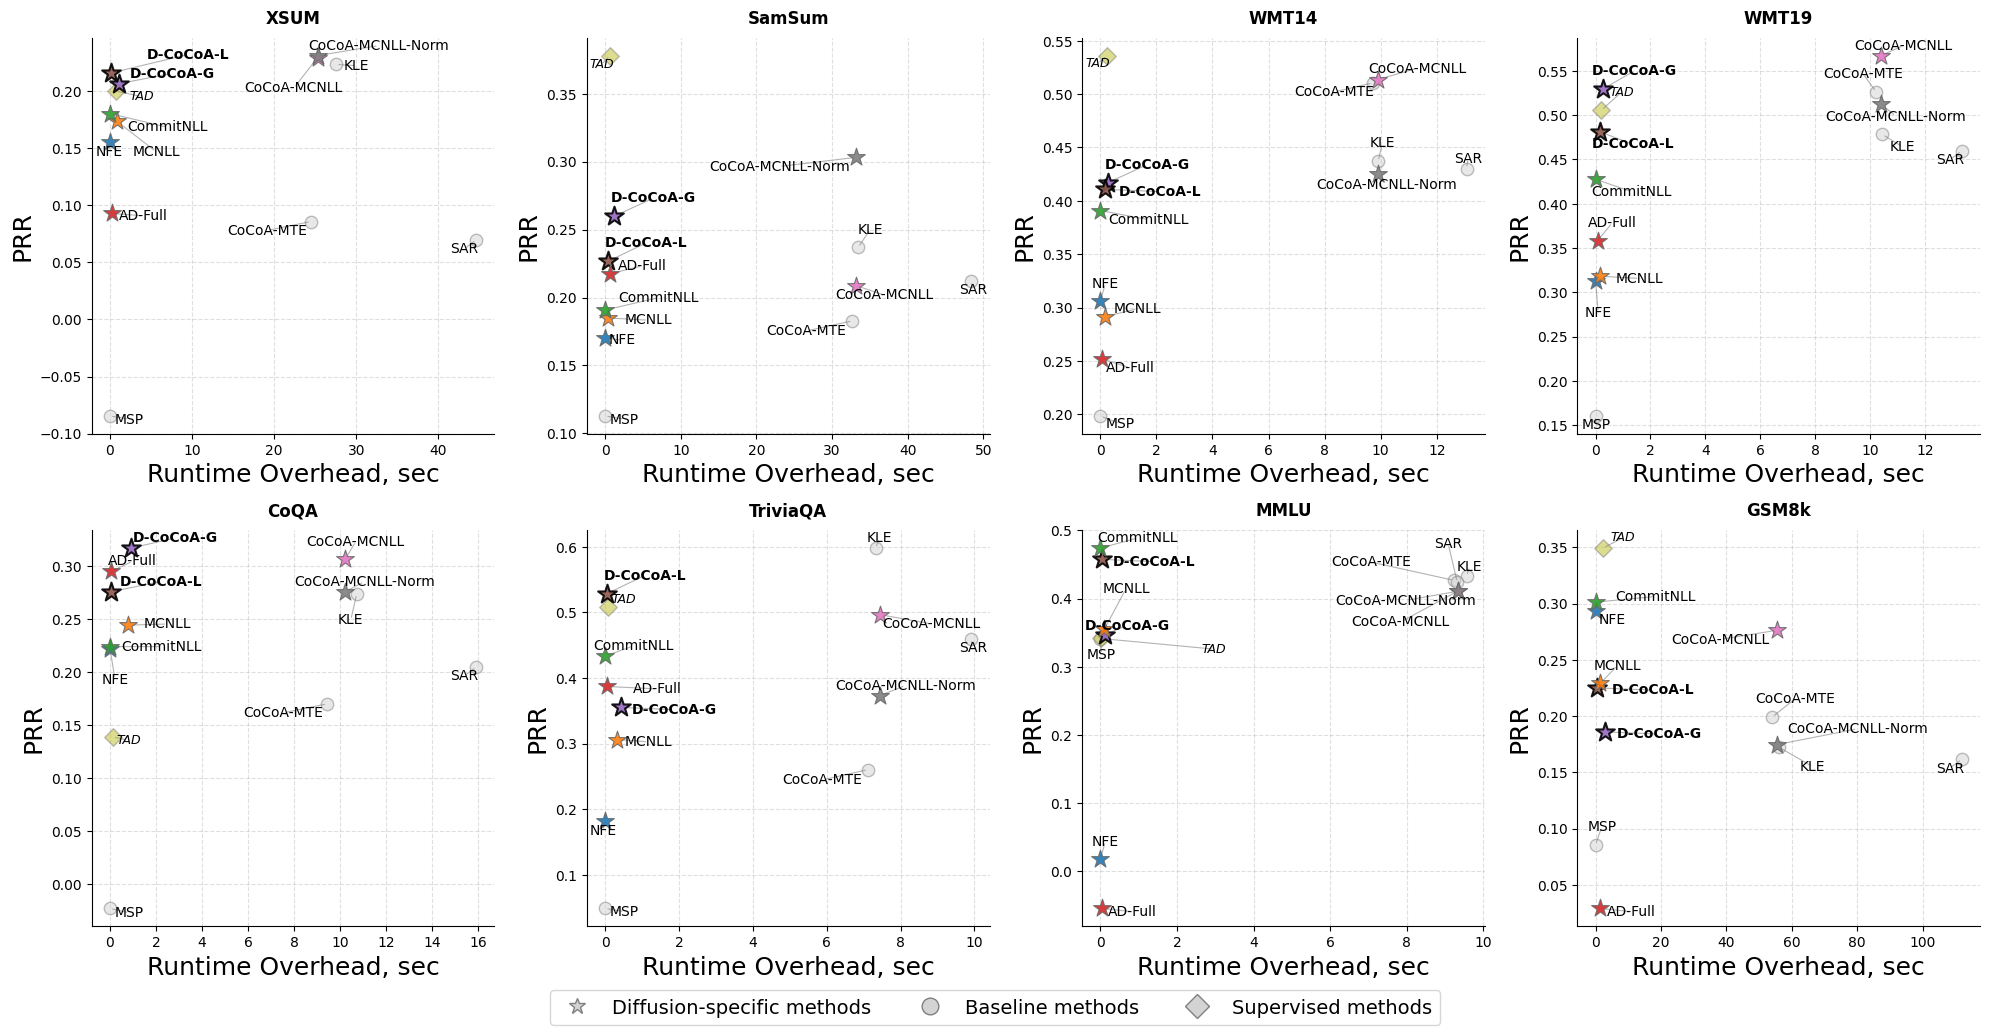

In [314]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
from adjustText import adjust_text  # <-- Импортируем библиотеку для текста
from matplotlib.lines import Line2D

# Предполагается, что методы df_all_selected и methods_time уже заданы в вашем коде выше

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
dss = list(methods_time.keys())

classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Собираем все уникальные методы, чтобы назначить каждому свой цвет навсегда
all_methods = list(methods_time[dss[0]].keys())
# Используем палитру (если методов больше 10, используйте 'tab20')
cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

# Оптимизация: делаем Method индексом один раз, чтобы быстро доставать значения
df_indexed = df_all_selected.set_index(df_all_selected.columns[0])

for i in range(2):
    for j in range(4):
        idx = i * 4 + j
        # Если датасетов меньше 8, прячем пустые графики
        if idx >= len(dss):
            axes[i, j].set_visible(False)
            continue
            
        ds = dss[idx]
        vals = methods_time[ds]
        methods = list(vals.keys())
        
        texts = []  # <-- Создаем пустой список для сбора текстовых объектов
        x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText
        
        # Строим каждую точку отдельно, чтобы гибко менять стиль
        for m in methods:
            x_val = vals[m]
            y_val = df_indexed.loc[m, ds].item() # Достаем значение по индексу
            
            x_coords.append(x_val)
            y_coords.append(y_val)
            
            # Настройки по умолчанию
            marker_style = '*'
            size = 180
            edgecolor = 'dimgray' # <-- Тёмно-серая обводка лучше выделяет слипшиеся точки
            linewidth = 0.8       # <-- Тонкая линия обводки
            z_order = 6
            alpha = 0.9
            font_weight = 'normal'
            label_text = m
            
            # Выделяем Cocoa_NFE_Trace_MC
            if m == 'D-CoCoA-G':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5         
                font_weight = 'bold'
            elif m == 'D-CoCoA-L':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5         
                font_weight = 'bold'
            # Выделяем TAD (Supervised outlier)
            elif m == 'TAD':
                marker_style = 'D'  # Ромб
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                # label_text = f"{m}\n(Supervised)" 
                edgecolor = 'gray'
                linewidth = 1.0
            elif m in classical_list:
                marker_style = 'o'  # Квадрат для классических методов
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                edgecolor = 'gray'
                linewidth = 1.0
                # font_weight = 'bold'
                
            # Рисуем точку
            axes[i, j].scatter(
                x_val, y_val, 
                s=size, 
                c=[method_colors[m]], 
                marker=marker_style, 
                edgecolors=edgecolor,
                linewidth=linewidth,
                alpha=alpha,
                zorder=z_order
            )
            
            # Создаем текст и добавляем его в список texts (ВМЕСТО annotate)
            txt = axes[i, j].text(
                x_val, y_val, label_text,
                ha='center', va='center', # Центрируем, adjustText сам их сдвинет
                fontsize=10 if m != 'TAD' else 9,
                fontweight=font_weight,
                fontstyle='italic' if m == 'TAD' else 'normal',
                zorder=11,
                # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
            )
            texts.append(txt)
            
        # <-- МАГИЯ ЗДЕСЬ: автоматически расталкиваем текст, чтобы он не перекрывал точки и друг друга
        # adjust_text(
        #     texts, 
        #     x=x_coords, # Передача координат сильно помогает алгоритму
        #     y=y_coords,
        #     ax=axes[i, j], 
        #     arrowprops=dict(arrowstyle="-", color='gray', lw=0.5, alpha=0.6),
        #     expand_points=(1.5, 1.5), 
        #     expand_text=(1.2, 1.2)    
        # )

        # adjust_text(
        #     texts, 
        #     x=x_coords,
        #     y=y_coords,
        #     ax=axes[i, j], 
        #     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),

        #     expand_points=(2.0, 2.0),   # increase distance from points
        #     expand_text=(1.8, 1.8),     # increase distance between labels

        #     force_text=(0.8, 0.8),      # stronger repulsion between texts
        #     force_points=(0.5, 0.5),    # stronger push away from points

        #     lim=200                     # more iterations → better layout
        # )

        adjust_text(
            texts, 
            x=x_coords,
            y=y_coords,
            ax=axes[i, j], 
            arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
            expand_points=(5.0, 5.0), 
            expand_text=(2.5, 2.5),
            force_points=(5.0, 5.0),
            force_text=(1.0, 1.0),
            force_explode=(1.7, 1.7),
            iterations=500,
            min_arrow_len=1,
        )

        # legend_elements = [
        #     Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
        # ]

        # axes[i, j].legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)
            
        # Эстетика подграфика
        axes[i, j].set_title(ds, fontsize=12, fontweight='bold', pad=10)
        axes[i, j].set_xlabel("Runtime Overhead, sec", fontsize=18, color='black')
        axes[i, j].set_ylabel("PRR", fontsize=18, color='black')
        
        # Красивая сетка и рамки
        axes[i, j].grid(True, linestyle='--', alpha=0.4, zorder=0)
        axes[i, j].spines['top'].set_visible(False)
        axes[i, j].spines['right'].set_visible(False)

# ВЫНОС ЛЕГЕНДЫ ВНИЗ (чтобы не перекрывала данные на 8 графиках)
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
plt.tight_layout()
fig.subplots_adjust(bottom=0.15) # Сдвигаем графики вверх
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=14, frameon=True, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig("../workdir/perf_vs_comp.png", dpi=300, bbox_inches='tight') # Улучшено качество сохранения
plt.savefig("../workdir/perf_vs_comp.pdf", bbox_inches='tight')
plt.show()


/tmp/ipykernel_1589770/234349288.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


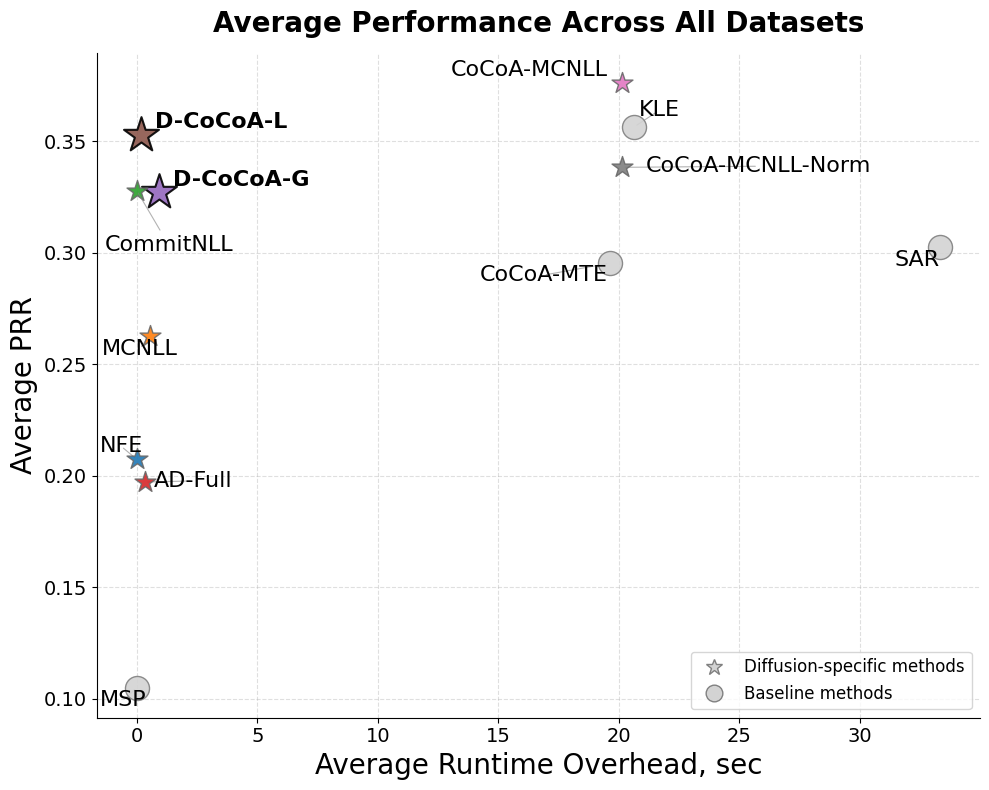

In [315]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import pandas as pd
from adjustText import adjust_text
from matplotlib.lines import Line2D

# --- 1. ПОДГОТОВКА И УСРЕДНЕНИЕ ДАННЫХ ---
dss = list(methods_time.keys())
all_methods = list(methods_time[dss[0]].keys())
df_indexed = df_all_selected.set_index(df_all_selected.columns[0])

avg_time = {}
avg_prr = {}

manual_offsets = {
    'CommitNLL':  (0.0,  0.04),   # пример: сдвинуть вправо и вверх
}

# --- 1. КОНФИГУРАЦИЯ ---
classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Вычисляем средние значения для каждого метода
for m in all_methods:
    # Собираем время метода m по всем датасетам и берем среднее
    times = [methods_time[ds][m] for ds in dss if m in methods_time[ds]]
    if times:
        avg_time[m] = np.mean(times)
        
    # Берем нужную строку (метод), берем столбцы датасетов и считаем среднее
    # pd.to_numeric нужен на случай, если какие-то данные считались строками
    avg_prr[m] = pd.to_numeric(df_indexed.loc[m, dss]).mean()

# --- 2. НАСТРОЙКА ОДНОГО ГРАФИКА ---
# Создаем только одну картинку, размер можно сделать поменьше, чем для сетки
fig, ax = plt.subplots(figsize=(10, 8)) 

cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

texts = []
manual_offsets = {
    # 'D-CoCoA-G': (0.0, 0.015),  # Сдвигаем текст D-CoCoA-G на 0.015 вверх по оси Y
    # 'D-CoCoA-L': (0.0, 0.015), # Раскомментируйте, если L тоже нужно поднять
    'CommitNLL': (1.5, 0.0),   # Раскомментируйте, если хотите сдвинуть вправо
}

x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText
# --- 3. ОТРИСОВКА ---
for m in all_methods:
    if m == "TAD": continue
    # Если для метода почему-то нет средних (например, пропуски в данных), пропускаем
    if m not in avg_time or m not in avg_prr or pd.isna(avg_prr[m]):
        continue
        
    x_val = avg_time[m]
    y_val = avg_prr[m]
    
    # Настройки по умолчанию (сохранены из вашего кода)
    marker_style = '*'
    size = 250            # Чуть увеличил для одиночного графика
    edgecolor = 'dimgray'
    linewidth = 1.0
    z_order = 6
    alpha = 0.9
    font_weight = 'normal'
    label_text = m
    
    # Выделяем CoCoA-NFE
    if m == 'D-CoCoA-L':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    elif m == 'D-CoCoA-G':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    # Выделяем TAD (Supervised)
    elif m == 'TAD':
        marker_style = 'D'  
        size = 180
        alpha = 0.5        
        z_order = 2        
        label_text = f"{m}\n(Supervised)" 
        edgecolor = 'gray'
        linewidth = 1.0
    elif m in classical_list:
        marker_style = 'o'  # Квадрат для классических методов
        size = 300
        edgecolor = 'black'
        linewidth = 1.2
        z_order = 4
        # font_weight = 'bold'
        edgecolor = 'gray'
        linewidth = 1.0
        
    # Рисуем точку
    ax.scatter(
        x_val, y_val, 
        s=size, 
        c=[method_colors[m]], 
        marker=marker_style, 
        edgecolors=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        zorder=z_order
    )

    if m == 'CommitNLL':
        pass
    else:
        x_coords.append(x_val)
        y_coords.append(y_val)

        va_alignment = "center"
        ha_alignment = "center"
        text_y = y_val  # по умолчанию текст на уровне точки
        if m in ['D-CoCoA-G', 'KLE']:
            # Поднимаем текст по оси Y (значение 0.012 можно увеличить/уменьшить)
            # text_y = y_val + 0.012 
            # Якорим текст за его нижний край, чтобы он весь был НАД точкой
            va_alignment = 'bottom' 
            ha_alignment = "left"
        elif m in ['CommitNLL']:
            va_alignment = 'top' 
            ha_alignment = "right"
            # text_y = y_val - 0.012

        # Создаем текст
        txt = ax.text(
            x_val, text_y, label_text,
            ha=ha_alignment, va=va_alignment,
            fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
            fontweight=font_weight,
            fontstyle='italic' if m == 'TAD' else 'normal',
            zorder=11,
            # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
        )
        texts.append(txt)
    
adjust_text(
    texts, 
    x=x_coords,
    y=y_coords,
    ax=ax, 
    arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),   # отступ от маркера (конец стрелки)),
    expand_points=(5.0, 5.0),  # главный параметр — отступ от маркера
    expand_text=(1.5, 1.5),
    force_points=(3.5, 3.5),   # сила отталкивания от маркеров
    force_text=(1.5, 1.5),     # слабое отталкивание между подписями
    min_arrow_len=5,
    iterations=500,
)

# for txt in texts:
#     if txt.get_text() == 'CommitNLL':
#         x, y = txt.get_position()
#         txt.set_position((x-1, y - 0.008))  # подбери нужное смещение
#         break

ax.annotate(
    'CommitNLL',
    xy=(avg_time['CommitNLL'], avg_prr['CommitNLL']),  # конец стрелки — точка данных
    xytext=(avg_time['CommitNLL'] + 4, avg_prr['CommitNLL'] - 0.02),  # позиция текста
    ha='right', va='top',
    fontsize=16,
    arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),
    zorder=11,
)

# --- 4. ЭСТЕТИКА ---
ax.set_title("Average Performance Across All Datasets", fontsize=20, fontweight='bold', pad=15)
ax.set_xlabel("Average Runtime Overhead, sec", fontsize=20, color='black')
ax.set_ylabel("Average PRR", fontsize=20, color='black')

# --- 5. ЛЕГЕНДА (Только по знакам) ---
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)

ax.grid(True, linestyle='--', alpha=0.4, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=14)  # increase tick label size

plt.tight_layout()

# Сохраняем с новым именем, чтобы не перезаписать файл с сеткой
plt.savefig("../workdir/avg_perf_vs_comp.png", dpi=300, bbox_inches='tight')
plt.savefig("../workdir/avg_perf_vs_comp.pdf", bbox_inches='tight')
plt.show()

In [203]:
avg_time['CoCoA-MCNLL'] / avg_time['D-CoCoA-G'], avg_time['CoCoA-MCNLL'] / avg_time['D-CoCoA-L'], avg_time['KLE'] / avg_time['D-CoCoA-L']

(22.157599051285597, 108.34802161675645, 111.0592608661851)

## Dream by Vlad

In [316]:
# df1_dream = pd.read_csv("../workdir/dream_7b_cache_results_1.csv", header=[0, 1])
# df1_dream = df1_dream[df1_dream.columns[:-2]]
# df2_dream = pd.read_csv("../workdir/dream_7b_cache_results_2.csv", header=[0, 1])
# df2_dream = df2_dream[df2_dream.columns[:-2]]
# df_dream = pd.merge(df1_dream, df2_dream, left_on=[df1_dream.columns[0]], right_on=[df2_dream.columns[0]], how='outer')
# df_dream = df_dream.drop(columns=[df2_dream.columns[0]])
df_dream = pd.read_csv("../workdir/dream_7b_postfix_results.csv", header=[0, 1])
df_dream = df_dream.drop(df_dream.columns[1], axis=1)
df_dream = df_dream.drop(df_dream.columns[5], axis=1)
df_dream = df_dream[df_dream.columns[:-4]]

df_dream_wmt = pd.read_csv("../workdir/dream_wmt_main_simple_results.csv", header=[0, 1])
df_dream_wmt = df_dream_wmt[df_dream_wmt.columns[:-2]]
df_dream = pd.merge(df_dream, df_dream_wmt, left_on=[df_dream.columns[0]], right_on=[df_dream_wmt.columns[0]], how='outer')
df_dream = df_dream.drop(columns=[df_dream_wmt.columns[0]])
df_dream = df_dream[np.array(df_dream.columns.to_list())[[0,6,1,7,8,2,3,4,5]]]

df_dream_cocoal = pd.read_csv("../workdir/dream_diffusion_last_results.csv", header=[0, 1])
df_dream_cocoal = df_dream_cocoal.drop(df_dream_cocoal.columns[8], axis=1)
df_dream_cocoal = df_dream_cocoal.drop(df_dream_cocoal.columns[6], axis=1)
df_dream_cocoal = df_dream_cocoal.drop(df_dream_cocoal.columns[4], axis=1)
df_dream_cocoal = df_dream_cocoal.drop(df_dream_cocoal.columns[2], axis=1)
df_dream_cocoal = df_dream_cocoal[df_dream_cocoal.columns[:-2]]
df_dream_cocoal = df_dream_cocoal[np.array(df_dream_cocoal.columns.to_list())[[0,6,5,7,8,3,4,1,2]]]
df_dream_cocoal.columns = [df_dream.columns[0]] + list(df_dream_cocoal.columns[1:])

df_dream = pd.concat([df_dream, df_dream_cocoal], ignore_index=True, axis=0)

path = "/home/artem.shelmanov/artemvazhentsev/uncertainty_dllm/workdir/dream_baselines_results_new.csv"
df_dream_baselines = pd.read_csv(path, header=[0, 1])
df_dream_baselines = df_dream_baselines[df_dream_baselines.columns[:-2]]

df_dream_baselines = df_dream_baselines.drop(df_dream_baselines.columns[8], axis=1)
df_dream_baselines = df_dream_baselines.drop(df_dream_baselines.columns[6], axis=1)
df_dream_baselines = df_dream_baselines.drop(df_dream_baselines.columns[4], axis=1)
df_dream_baselines = df_dream_baselines.drop(df_dream_baselines.columns[2], axis=1)

df_dream_baselines = df_dream_baselines[np.array(df_dream_baselines.columns.to_list())[[0,6,5,7,8,3,4,1,2]]]
df_dream_baselines.columns = pd.MultiIndex.from_tuples([df_dream.columns[0]] + list(df_dream_baselines.columns[1:]))

# df_dream_baselines.loc[:, ('', "Mean")] = df_dream_baselines[df_dream_baselines.columns[1:]].mean(axis=1)
# df_dream_baselines.loc[:, ('', "Mean Rank")] = df_dream_baselines[df_dream_baselines.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

df_dream_1 = pd.read_csv("../workdir/results/dream_setup_b_with_train_results.csv", header=[0, 1])
df_dream_1 = df_dream_1[df_dream_1.columns[:-2]]

df_dream_2 = pd.read_csv("../workdir/results/dream_setup_c_train_only_results.csv", header=[0, 1])
df_dream_2 = df_dream_2[df_dream_2.columns[:-2]]
df_dream_2 = df_dream_2.drop(df_dream_2.columns[5], axis=1)
df_dream_2 = df_dream_2.drop(df_dream_2.columns[3], axis=1)

df_dream_train = pd.merge(df_dream_1, df_dream_2, left_on=[df_dream_1.columns[0]], right_on=[df_dream_2.columns[0]], how='inner')
df_dream_train = df_dream_train.drop(columns=[df_dream_2.columns[0]])

df_dream_train = df_dream_train[np.array(df_dream_train.columns.to_list())[[0,8,7,1,2,5,6,3,4]]]
df_dream_train.columns = df_dream.columns

df_dream = pd.concat([df_dream, df_dream_baselines], ignore_index=True, axis=0)
df_dream = pd.concat([df_dream, df_dream_train], ignore_index=True, axis=0)
df_dream.drop_duplicates(subset=df_dream.columns[0], keep='first', inplace=True)

df_dream.loc[:, ('', "Mean")] = df_dream[df_dream.columns[1:]].mean(axis=1)
# df_dream.loc[:, ('', "Mean Rank")] = df_dream[df_dream.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)


In [317]:
# df_dream_train = pd.read_csv("../workdir/dream_train_only_results.csv", header=[0, 1])
# df_dream_train = df_dream_train[df_dream_train.columns[:-2]]
# df_dream_train = df_dream_train.drop(df_dream_train.columns[3], axis=1)
# df_dream_train = df_dream_train.drop(df_dream_train.columns[1], axis=1)

# df_dream_train_wmt = pd.read_csv("../workdir/dream_wmt14_fren_with_train_results.csv", header=[0, 1])
# df_dream_train_wmt = df_dream_train_wmt[df_dream_train_wmt.columns[:-2]]

# df_dream_train = pd.merge(df_dream_train, df_dream_train_wmt, left_on=[df_dream_train.columns[0]], right_on=[df_dream_train_wmt.columns[0]], how='inner')
# df_dream_train = df_dream_train.drop(columns=[df_dream_train_wmt.columns[0]])

# df_dream_train.loc[:, ('', "Mean")] = df_dream_train[df_dream_train.columns[1:]].mean(axis=1)
# df_dream_train.loc[:, ('', "Mean Rank")] = df_dream_train[df_dream_train.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

# df_dream_train.sort_values(df_dream_train.columns[-2], ascending=False).style.background_gradient(axis=0)

In [318]:
df_dream.sort_values(df_dream.columns[-1], ascending=False).style.background_gradient(axis=0)

,TruthfulQA,XSum,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
545,CocoaMCMaskedNormalizedNLL,0.294996,0.304339,0.705287,0.723376,0.286796,0.667408,0.739936,0.481953,0.525511
550,CocoaMTE,0.252185,0.282637,0.716902,0.760422,0.241661,0.580565,0.735175,0.412811,0.497795
615,LookBackLens,0.340827,0.288651,0.717001,0.740855,0.321845,0.639573,0.595851,0.313188,0.494724
547,LUQ,0.319249,0.302029,0.459233,0.501614,0.307997,0.662558,0.636857,0.593853,0.472924
144,CocoaMCMaskedNormalizedNLLCrossEncoderBlockAvgTraceNFE,0.229581,0.260783,0.584329,0.629135,0.340211,0.622284,0.746580,0.363390,0.472037
174,CocoaMCMaskedNormalizedNLLDebertaContraBlockAvgTraceNFE,0.285149,0.307175,0.561178,0.606419,0.313768,0.584683,0.722444,0.383005,0.470478
549,KernelLanguageEntropy,0.343043,0.289651,0.471183,0.550434,0.321262,0.669967,0.516665,0.601230,0.470429
158,CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceProgressNFE,0.166089,0.237028,0.591094,0.638030,0.339832,0.645461,0.750622,0.363458,0.466452
156,CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE,0.141803,0.224474,0.639430,0.682762,0.340229,0.622284,0.746647,0.331740,0.466171


In [319]:
# order = ['MaximumSequenceProbability', "SAR", "CocoaMTE", "KernelLanguageEntropy", "TAD", 
#          "MCMaskedNLL", "MCMaskedNormalizedNLL", "NFEUncertainty", 
#          "TraceProbs_avg", "TraceEntropy_avg", "ConfidenceAtCommit_avg",
#          "AvgDissimilarityFullTrace", "AvgDissimilarityFullTraceProgress",
#          "CocoaMCMaskedNLL", "CocoaMCMaskedNormalizedNLL", 
#          "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace"]
# order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

# df_dream_selected = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
# df_dream_selected[df_dream_selected.columns[0]] = df_dream_selected[df_dream_selected.columns[0]].replace({"MCMaskedNormalizedNLL": "MCNLL-Norm", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCNLL-Norm", "MaximumSequenceProbability": "MSP", 
#                                                                                                            "ConfidenceAtCommit_avg": "CommitNLL", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", 
#                                                                                                            "AvgDissimilarityFullTraceProgress": "WeightedAD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G", "KernelLanguageEntropy": "KLE", 
#                                                                                                            "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", 
#                                                                                                            "EigenScore": "EigenScore", "LUQ": "LUQ", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L", "TraceProbs_avg": "TrajProbs"})

# df_dream_selected.columns = pd.MultiIndex.from_tuples(
#     [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_selected.columns]
# )

# df_dream_selected.style.background_gradient(axis=0)

In [320]:
order = ['MaximumSequenceProbability', "SAR", "CocoaMTE", "KernelLanguageEntropy", "TAD", 
         "MCMaskedNLL", "NFEUncertainty",  "AvgDissimilarityFullTrace", "ConfidenceAtCommit_avg",
         "CocoaMCMaskedNLL", "CocoaMCMaskedNormalizedNLL", 
         "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace"]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_selected = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_selected[df_dream_selected.columns[0]] = df_dream_selected[df_dream_selected.columns[0]].replace({"MCMaskedNormalizedNLL": "MCNLL-Norm", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCNLL-Norm", "MaximumSequenceProbability": "MSP", 
                                                                                                           "ConfidenceAtCommit_avg": "CommitNLL", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", 
                                                                                                           "AvgDissimilarityFullTraceProgress": "WeightedAD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G", "KernelLanguageEntropy": "KLE", 
                                                                                                           "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", 
                                                                                                           "EigenScore": "EigenScore", "LUQ": "LUQ", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L", "TraceProbs_avg": "TrajProbs"})

df_dream_selected.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_selected.columns]
)

df_dream_selected.style.background_gradient(axis=0)

,TruthfulQA,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
0,MSP,-0.048326,0.047850,-0.071062,-0.035379,0.166390,0.148581,0.705367,0.160192,0.134202
1,SAR,0.137219,0.199070,0.388361,0.466189,0.283582,0.597775,0.734987,0.326066,0.391656
2,CoCoA-MTE,0.252185,0.282637,0.716902,0.760422,0.241661,0.580565,0.735175,0.412811,0.497795
3,KLE,0.343043,0.289651,0.471183,0.550434,0.321262,0.669967,0.516665,0.601230,0.470429
4,TAD,0.440323,0.421971,0.571386,0.483518,0.232854,0.513740,0.019511,0.385416,0.383590
5,MCNLL,0.088768,0.029371,0.000184,0.056271,0.246179,0.478434,0.749947,0.275269,0.240553
6,NFE,0.002176,-0.021605,0.379584,0.489532,0.354123,0.499987,0.029923,0.347974,0.260212
7,AD-Full,0.045497,0.157783,0.562873,0.617345,0.260537,0.444142,0.709149,0.086946,0.360534
8,CommitNLL,0.108834,0.027969,0.396540,0.532034,0.402280,0.683310,0.522404,0.393624,0.383374


In [321]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_selected).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MSP & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.05 & \cellcolor[rgb]{0.7125994850980393,0.779529089882353,0.9730307285392157} 0.05 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.07 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.04 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.17 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.15 & \cellcolor[rgb]{0.9150932609745098,0.6523663817764705,0.6274457140333334} 0.71 & \cellcolor[rgb]{0.6996157421568627,0.7642642360784314,0.9642295513921568} 0.16 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.13 \\
SAR & \cellcolor[rgb]{0.8694129974705882,0.9112858109117647,0.98413053191176

In [322]:
def get_time(path, base=False):
    methods = {
        "MSP": ["MaximumSequenceProbability"],
        "NFE": ["NFEUncertainty"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "CommitNLL": ["ConfidenceAtCommit_avg"],
        # "TraceEntropy": ["TraceEntropy_avg"],
        "AD-Full": ["AvgDissimilarityFullTrace", "greedy_sentence_similarity_full_trace"],
        "D-CoCoA-G": ["CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "greedy_sentence_similarity_full_trace", "mc_masked_ll"],
        "D-CoCoA-L": ["CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace", "greedy_sentence_similarity_block"],
        "MSP": ["MaximumSequenceProbability"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "KLE": ["KernelLanguageEntropy", "semantic_matrix_entail", "sample_texts"],
        # "DegMat": ["DegMat_NLI_score_entail", "semantic_matrix_entail", "sample_texts"],
        # "LUQ": ["LUQ", "semantic_matrix_entail_logits", "sample_texts"],
        "CoCoA-MTE": ["CocoaMTE", "greedy_sentence_similarity", "sample_texts"],
        # "EigenScore": ["EigenScore", "sample_embeddings"],
        "CoCoA-MCNLL": ["CocoaMCMaskedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_ll"],
        "CoCoA-MCNLL-Norm" : ["CocoaMCMaskedNormalizedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_normalized_ll"],
        "TAD": ["TAD", "attention_features"],
        "SAR": ["SAR", "sample_sentence_similarity", "sample_texts"],
        # "SemanticEntropy": ["SemanticEntropy", "sample_texts", "semantic_matrix_entail", "semantic_classes_entail"],
    }

    times = {}
    seen_stats = {}
    
    if isinstance(path, list):
        for p in path:
            man = torch.load(p, weights_only=False)
            
            for method in methods.keys():
                for stat in methods[method]:
                    if method in seen_stats.keys() and stat in seen_stats[method]:
                        # print("seen", method, stat)
                        continue
                    if stat is None:
                        times[method] = 0
                        continue
                    if methods[method][0] not in man["time_stats"].keys():
                        # times[method] = 0
                        continue
                    elif method not in times.keys():
                        times[method] = 0
                    # print(method, stat)
                    scores = np.array(man["time_stats"][stat])
                    seen_stats[method] = seen_stats.get(method, set()).union(set([stat]))
                    if len(scores) == 0:
                        print(p, stat, scores)
                        # print(seen_stats)
                    try:
                        times[method] += np.array(scores[1:])
                    except Exception as e:
                        # print(e, len(times[method]), len(scores)) 
                        if len(times[method]) == (len(scores[1:]) - 1):
                            times[method] += np.array(scores[2:])
                        elif len(times[method]) == (len(scores[1:]) + 1):
                            times[method] += np.array([0] +scores[2:])
                        else:
                            print(p, stat, scores)
    else:
        man = torch.load(path, weights_only=False)
        
        for method in methods.keys():
            times[method] = 0
            for stat in methods[method]:
                if stat is None:
                    times[method] = 0
                    continue
                scores = np.array(man["time_stats"][stat])
                if len(scores) == 0:
                    print(stat, scores)
                times[method] += np.array(scores[1:])
    return times

In [323]:
order = ['MSP', 'NFE', 'MCNLL', 'CommitNLL', 'AD-Full', 'D-CoCoA-G', 'D-CoCoA-L', 'KLE', 'CoCoA-MTE', 'CoCoA-MCNLL', 'CoCoA-MCNLL-Norm', 'TAD', 'SAR']

In [324]:
datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "SamSum": [
            "../workdir/results/pickles/setup_c_train_only/samsum.pkl",
            "../workdir/results/pickles/cocoaL/samsum.pkl",
            "../workdir/results/pickles/setup_b_with_train/samsum copy.pkl",
            # "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
            "../workdir/results/pickles/setup_d_diffusion_merged/samsum.pkl"
        ],
        "GSM8k": [
            "../workdir/results/pickles/setup_c_train_only/gsm8k.pkl",
            "../workdir/results/pickles/cocoaL/gsm8k.pkl",
            "../workdir/results/pickles/setup_b_with_train/gsm8k copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/gsm8k.pkl"
        ],
        "CoQA": [
            "../workdir/results/pickles/setup_c_train_only/coqa.pkl",
            "../workdir/results/pickles/cocoaL/coqa.pkl",
            "../workdir/results/pickles/setup_b_with_train/coqa copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/coqa.pkl"
        ],
        "TriviaQA": [
            "../workdir/results/pickles/setup_c_train_only/triviaqa.pkl",
            "../workdir/results/pickles/cocoaL/triviaqa.pkl",
            "../workdir/results/pickles/setup_b_with_train/triviaqa copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/triviaqa.pkl"
        ],
        "MMLU": [
            "../workdir/results/pickles/setup_c_train_only/mmlu.pkl",
            "../workdir/results/pickles/cocoaL/mmlu.pkl",
            "../workdir/results/pickles/setup_b_with_train/mmlu copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/mmlu.pkl"
        ],
        "WMT14": [
            "../workdir/results/pickles/setup_b_with_train/wmt14_fren.pkl",
            "../workdir/results/pickles/cocoaL/wmt14_fren.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/wmt14_fren.pkl"
        ],
        "WMT19": [
            "../workdir/results/pickles/setup_b_with_train/wmt19_deen.pkl",
            "../workdir/results/pickles/cocoaL/wmt19_deen.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/wmt19_deen.pkl"
        ],
        "XSUM": [
            "../workdir/results/pickles/setup_c_train_only/xsum.pkl",
            "../workdir/results/pickles/setup_b_with_train/xsum copy.pkl",
            "../workdir/results/pickles/cocoaL/xsum.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/xsum.pkl"
        ],
    }
}


dfs_time = {}
all_paths = []
for model in models:
    dfs_time[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        try:
            final_path = paths[model][ds_name]
        except:
            continue
        if final_path is not None:
            print(final_path)
            df = get_time(final_path, base=False)
            dfs_time[model][ds_name] = df


['../workdir/results/pickles/setup_c_train_only/xsum.pkl', '../workdir/results/pickles/setup_b_with_train/xsum copy.pkl', '../workdir/results/pickles/cocoaL/xsum.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/xsum.pkl']
['../workdir/results/pickles/setup_c_train_only/samsum.pkl', '../workdir/results/pickles/cocoaL/samsum.pkl', '../workdir/results/pickles/setup_b_with_train/samsum copy.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/samsum.pkl']
['../workdir/results/pickles/setup_b_with_train/wmt14_fren.pkl', '../workdir/results/pickles/cocoaL/wmt14_fren.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/wmt14_fren.pkl']
['../workdir/results/pickles/setup_b_with_train/wmt19_deen.pkl', '../workdir/results/pickles/cocoaL/wmt19_deen.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/wmt19_deen.pkl']
['../workdir/results/pickles/setup_c_train_only/coqa.pkl', '../workdir/results/pickles/cocoaL/coqa.pkl', '../workdir/results/pickles/setup_b_with_train/co

In [325]:
methods_time = {ds: {} for ds in dfs_time[model].keys()}
for ds in dfs_time[model]:
    for m in dfs_time[model][ds].keys():
        methods_time[ds][m] = np.mean(dfs_time[model][ds][m])

/tmp/ipykernel_1589770/168136776.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


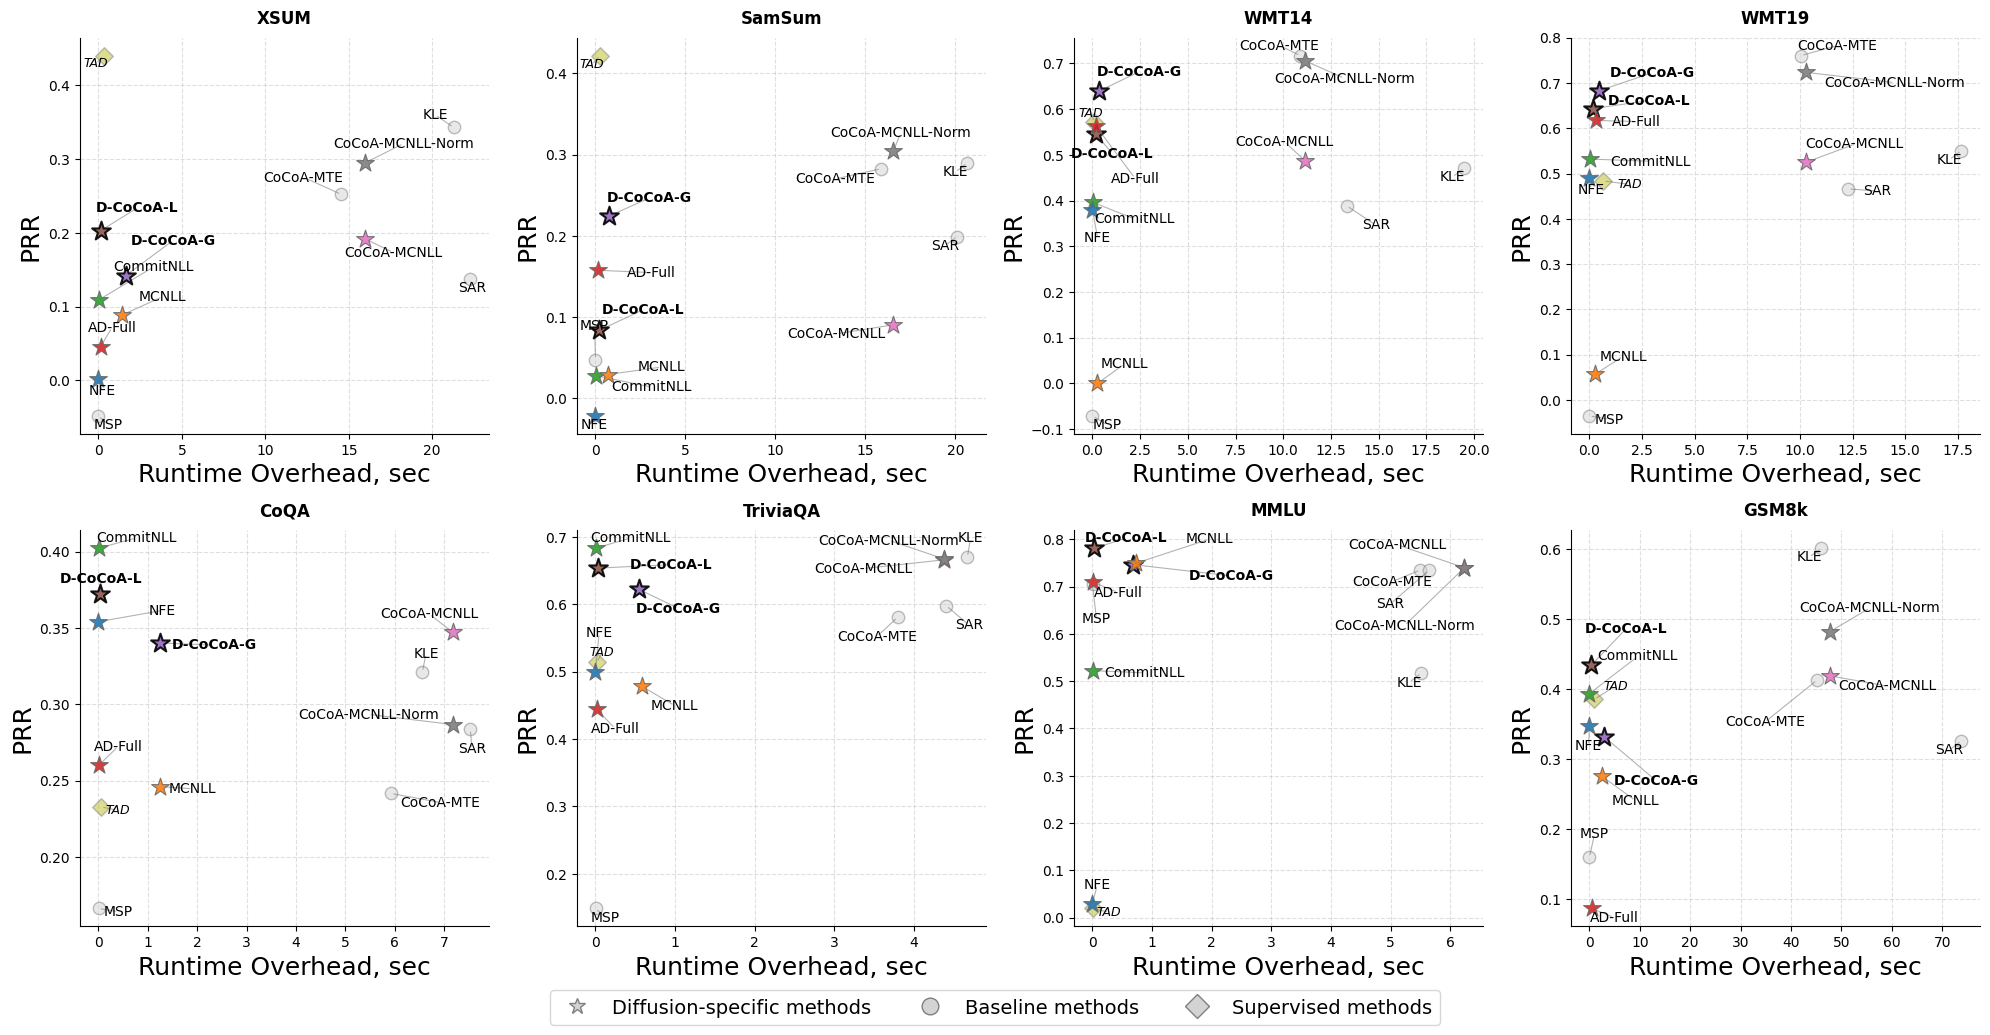

In [328]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
from adjustText import adjust_text  # <-- Импортируем библиотеку для текста
from matplotlib.lines import Line2D

# Предполагается, что методы df_dream_selected и methods_time уже заданы в вашем коде выше

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
dss = list(methods_time.keys())

classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Собираем все уникальные методы, чтобы назначить каждому свой цвет навсегда
all_methods = list(methods_time[dss[0]].keys())
# Используем палитру (если методов больше 10, используйте 'tab20')
cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in order:#all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

# Оптимизация: делаем Method индексом один раз, чтобы быстро доставать значения
df_indexed = df_dream_selected.set_index(df_dream_selected.columns[0])

for i in range(2):
    for j in range(4):
        idx = i * 4 + j
        # Если датасетов меньше 8, прячем пустые графики
        if idx >= len(dss):
            axes[i, j].set_visible(False)
            continue
            
        ds = dss[idx]
        vals = methods_time[ds]
        methods = list(vals.keys())
        
        texts = []  # <-- Создаем пустой список для сбора текстовых объектов
        x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText

        # Строим каждую точку отдельно, чтобы гибко менять стиль
        for m in methods:
            # if m == "TAD": continue
            x_val = vals[m]
            y_val = df_indexed.loc[m, ds].item() # Достаем значение по индексу

            x_coords.append(x_val)
            y_coords.append(y_val)
            
            # Настройки по умолчанию
            marker_style = '*'
            size = 180
            edgecolor = 'dimgray' # <-- Тёмно-серая обводка лучше выделяет слипшиеся точки
            linewidth = 0.8       # <-- Тонкая линия обводки
            z_order = 6
            alpha = 0.9
            font_weight = 'normal'
            label_text = m
            
            # Выделяем Cocoa_NFE_Trace_MC
            if m == 'D-CoCoA-G':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5
                # alpha = 0.5         
                font_weight = 'bold'
            elif m == 'D-CoCoA-L':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5     
                # alpha = 0.5    
                font_weight = 'bold'
            # Выделяем TAD (Supervised outlier)
            elif m == 'TAD':
                marker_style = 'D'  # Ромб
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                # label_text = f"{m}\n(Supervised)" 
                edgecolor = 'gray'
                linewidth = 1.0
            elif m in classical_list:
                marker_style = 'o'  # Квадрат для классических методов
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                edgecolor = 'gray'
                linewidth = 1.0
                # font_weight = 'bold'
                
            # Рисуем точку
            axes[i, j].scatter(
                x_val, y_val, 
                s=size, 
                c=[method_colors[m]], 
                marker=marker_style, 
                edgecolors=edgecolor,
                linewidth=linewidth,
                alpha=alpha,
                zorder=z_order
            )

            va = "center"
            ha = "center"
            if ds == "MMLU":
                if m == "CoCoA-MCNLL":
                    # va = "bottom"
                    pass
                if m == "CoCoA-MCNLL-Norm":
                    # ha = "left"
                    va = "bottom"
            
            # Создаем текст и добавляем его в список texts (ВМЕСТО annotate)
            txt = axes[i, j].text(
                x_val, y_val, label_text,
                ha=ha, va=va, # Центрируем, adjustText сам их сдвинет
                fontsize=10 if m != 'TAD' else 9,
                fontweight=font_weight,
                fontstyle='italic' if m == 'TAD' else 'normal',
                zorder=11,
                # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
            )
            texts.append(txt)
            
        # # <-- МАГИЯ ЗДЕСЬ: автоматически расталкиваем текст, чтобы он не перекрывал точки и друг друга
        # adjust_text(
        #     texts, 
        #     x=x_coords, # Передача координат сильно помогает алгоритму
        #     y=y_coords,
        #     ax=axes[i, j], 
        #     arrowprops=dict(arrowstyle="-", color='gray', lw=0.5, alpha=0.6), # Рисует тонкие линии от текста к точке, если текст сильно сдвинулся
        #     expand_points=(1.5, 1.5), # Сила отталкивания от точек
        #     expand_text=(1.2, 1.2)    # Сила отталкивания текстов друг от друга
        # )

        # axes[i, j].set_xscale('log')

        adjust_text(
            texts, 
            x=x_coords,
            y=y_coords,
            ax=axes[i, j], 
            arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
            expand_points=(5.0, 5.0), 
            expand_text=(4.5, 4.5),
            force_points=(5.0, 5.0),
            force_text=(1.0, 1.0),
            force_explode=(2.7, 2.7),
            iterations=5000,
            min_arrow_len=0.5,
        )

        # legend_elements = [
        #     Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='gray', markersize=12),
        # ]
        # axes[i, j].legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)
            
        # Эстетика подграфика
        axes[i, j].set_title(ds, fontsize=12, fontweight='bold', pad=10)
        axes[i, j].set_xlabel("Runtime Overhead, sec", fontsize=18, color='black')
        axes[i, j].set_ylabel("PRR", fontsize=18, color='black')
        
        # Красивая сетка и рамки
        axes[i, j].grid(True, linestyle='--', alpha=0.4, zorder=0)
        axes[i, j].spines['top'].set_visible(False)
        axes[i, j].spines['right'].set_visible(False)

        # axes[i, j].set_xscale('log')


# ВЫНОС ЛЕГЕНДЫ ВНИЗ (чтобы не перекрывала данные на 8 графиках)
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
plt.tight_layout()
fig.subplots_adjust(bottom=0.15) # Сдвигаем графики вверх
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=14, frameon=True, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig("../workdir/dream_perf_vs_comp.png", dpi=300, bbox_inches='tight') # Улучшено качество сохранения
plt.savefig("../workdir/dream_perf_vs_comp.pdf", bbox_inches='tight')
plt.show()


/tmp/ipykernel_1589770/2403576275.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


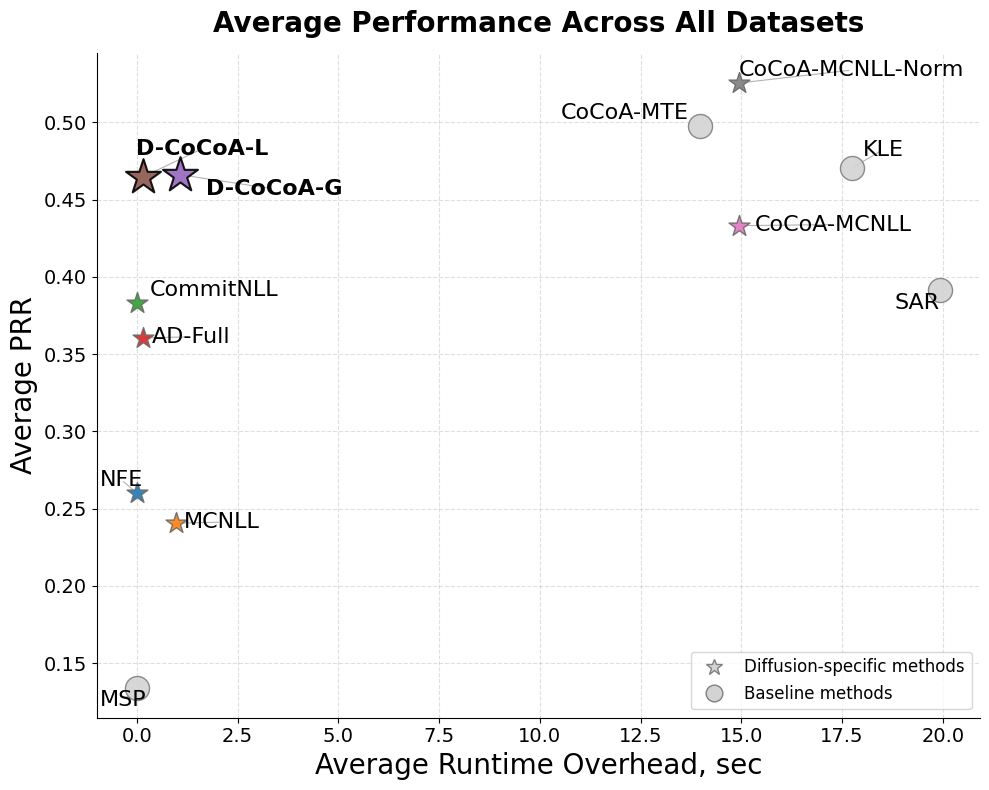

In [329]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import pandas as pd
from adjustText import adjust_text
from matplotlib.lines import Line2D

# --- 1. ПОДГОТОВКА И УСРЕДНЕНИЕ ДАННЫХ ---
dss = list(methods_time.keys())
all_methods = list(methods_time[dss[0]].keys())
df_indexed = df_dream_selected.set_index(df_dream_selected.columns[0])

avg_time = {}
avg_prr = {}

# --- 1. КОНФИГУРАЦИЯ ---
classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Вычисляем средние значения для каждого метода
for m in order:
    # if m == "TAD": continue
    # Собираем время метода m по всем датасетам и берем среднее
    times = [methods_time[ds][m] for ds in dss if m in methods_time[ds]]
    if times:
        avg_time[m] = np.mean(times)
        
    # Берем нужную строку (метод), берем столбцы датасетов и считаем среднее
    # pd.to_numeric нужен на случай, если какие-то данные считались строками
    avg_prr[m] = pd.to_numeric(df_indexed.loc[m, dss]).mean()

# --- 2. НАСТРОЙКА ОДНОГО ГРАФИКА ---
# Создаем только одну картинку, размер можно сделать поменьше, чем для сетки
fig, ax = plt.subplots(figsize=(10, 8)) 

cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in order:#all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

# method_colors = {m: cmap(i) for i, m in enumerate(all_methods)}

texts = []

x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText
# --- 3. ОТРИСОВКА ---
for m in order:#all_methods:
    if m == "TAD": continue
    # Если для метода почему-то нет средних (например, пропуски в данных), пропускаем
    if m not in avg_time or m not in avg_prr or pd.isna(avg_prr[m]):
        continue
        
    # x_coords.append(x_val)
    # y_coords.append(y_val)
    x_val = avg_time[m]
    y_val = avg_prr[m]
    
    # Настройки по умолчанию (сохранены из вашего кода)
    marker_style = '*'
    size = 250            # Чуть увеличил для одиночного графика
    edgecolor = 'dimgray'
    linewidth = 1.0
    z_order = 6
    alpha = 0.9
    font_weight = 'normal'
    label_text = m
    
    # Выделяем CoCoA-NFE
    if m == 'D-CoCoA-L':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    elif m == 'D-CoCoA-G':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    # Выделяем TAD (Supervised)
    elif m == 'TAD':
        marker_style = 'D'  
        size = 180
        alpha = 0.5        
        z_order = 2        
        label_text = f"{m}\n(Supervised)" 
        edgecolor = 'gray'
        linewidth = 1.0
    elif m in classical_list:
        marker_style = 'o'  # Квадрат для классических методов
        size = 300
        edgecolor = 'black'
        linewidth = 1.2
        z_order = 4
        # font_weight = 'bold'
        edgecolor = 'gray'
        linewidth = 1.0
        
    # Рисуем точку
    ax.scatter(
        x_val, y_val, 
        s=size, 
        c=[method_colors[m]], 
        marker=marker_style, 
        edgecolors=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        zorder=z_order
    )
    
    if False:#m == 'D-CoCoA-L':
        pass
    # Создаем текст
    else:
        va_alignment = "center"
        ha_alignment = "center"
        text_y = y_val  # по умолчанию текст на уровне точки
        if m in ['D-CoCoA-G', 'D-CoCoA-L', 'KLE']:
            # Поднимаем текст по оси Y (значение 0.012 можно увеличить/уменьшить)
            # text_y = y_val + 0.012 
            # Якорим текст за его нижний край, чтобы он весь был НАД точкой
            va_alignment = 'bottom' 
            ha_alignment = "left"
        # elif m in ['CommitNLL']:
        #     va_alignment = 'top' 
        #     ha_alignment = "right"
        #     text_y = y_val - 0.012

        # Создаем текст
        txt = ax.text(
            x_val, text_y, label_text,
            ha=ha_alignment, va=va_alignment,
            fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
            fontweight=font_weight,
            fontstyle='italic' if m == 'TAD' else 'normal',
            zorder=11,
            # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
        )
        texts.append(txt)
        x_coords.append(x_val)
        y_coords.append(y_val)
        # txt = ax.text(
        #     x_val, y_val, label_text,
        #     ha='center', va='center',
        #     fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
        #     fontweight=font_weight,
        #     fontstyle='italic' if m == 'TAD' else 'normal',
        #     zorder=11,
        #     # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
        # )
        # texts.append(txt)

# Расталкиваем текст
# adjust_text(
#     texts, 
#     x=x_coords, # Передача координат сильно помогает алгоритму
#     y=y_coords,
#     ax=ax, 
#     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
#     expand_points=(1.5, 1.5), 
#     expand_text=(1.2, 1.2)    
# )

adjust_text(
    texts, 
    x=x_coords,
    y=y_coords,
    ax=ax, 
    arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
    expand_points=(3.0, 3.0), 
    expand_text=(2.5, 2.5),
    force_points=(1.0, 1.0),
    force_text=(1.0, 1.0),
    force_explode=(0.7, 0.7),
    iterations=300,
)

# ax.annotate(
#     'D-CoCoA-L',
#     xy=(avg_time['D-CoCoA-L'], avg_prr['D-CoCoA-L']),  # конец стрелки — точка данных
#     xytext=(avg_time['D-CoCoA-L'], avg_prr['D-CoCoA-L']),  # позиция текста
#     ha='right', va='top',
#     fontsize=16,
#     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),
#     zorder=11,
# )
    
# --- 4. ЭСТЕТИКА ---
ax.set_title("Average Performance Across All Datasets", fontsize=20, fontweight='bold', pad=15)
ax.set_xlabel("Average Runtime Overhead, sec", fontsize=20, color='black')
ax.set_ylabel("Average PRR", fontsize=20, color='black')

# --- 5. ЛЕГЕНДА (Только по знакам) ---
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)

ax.grid(True, linestyle='--', alpha=0.4, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=14)  # increase tick label size

plt.tight_layout()

# Сохраняем с новым именем, чтобы не перезаписать файл с сеткой
plt.savefig("../workdir/dream_avg_perf_vs_comp.png", dpi=300, bbox_inches='tight')
plt.savefig("../workdir/dream_avg_perf_vs_comp.pdf", bbox_inches='tight')
plt.show()

In [216]:
df_baselines_ar = df_all.iloc[[47, 50, 61, 0, 2, 62,
                               51, 73, 68, 27, 7, 71,
                               32, 30, 14, 
                               67, 69, 42, 77]]

order = df_baselines_ar[df_baselines_ar.columns[0]].to_list()
order = [x.replace("16", "14") for x in order]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_ar_baselines = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_ar_baselines[df_dream_ar_baselines.columns[0]] = df_dream_ar_baselines[df_dream_ar_baselines.columns[0]].replace(
    {"MaximumSequenceProbability": "MSP", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCMaskedNLL", 
     "TraceEntropy_avg": "TraceEntropy", "AvgDissimilarityFullTrace": "AvgDissim", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "CoCoA-NFE", 
     "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCMaskedNormNLL", "TAD": "TAD", "SAR": "SAR", 
     "SAPLMA_decoder_14": "SAPLMA", "SATRMD_decoder": "SATRMD", "MonteCarloNormalizedSequenceEntropy": "MCNSE", "AttentionScore (layer=14)": "AttScore", "MeanTokenEntropy": "MTE",
     "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ"})

df_dream_ar_baselines.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_ar_baselines.columns]
)

df_dream_ar_baselines.style.background_gradient(axis=0)

,TruthfulQA,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
0,MSP,-0.048326,0.047850,-0.071062,-0.035379,0.166390,0.148581,0.705367,0.160192,0.134202
1,MTE,0.145989,0.247012,0.405370,0.443386,0.049327,0.191156,0.624695,0.138359,0.280662
2,Perplexity,0.025701,0.251572,0.153119,0.179650,0.129530,0.119640,0.558527,0.098569,0.189538
3,AttScore,-0.009923,0.046160,-0.140057,-0.119181,0.052594,0.130140,0.028936,0.194529,0.022900
4,CCP,-0.034045,0.092600,-0.065766,-0.033387,0.177630,0.146475,0.469422,0.136069,0.111125
5,RAUQ,0.024375,0.123196,0.083631,0.110816,0.165323,0.034508,0.550062,0.091456,0.147921
6,MCNSE,0.061165,0.128034,0.289343,0.356073,0.206955,0.523917,0.697075,0.019782,0.285293
7,SemanticEntropy,-0.026894,0.022457,0.094516,0.206446,0.274651,0.575410,0.761100,0.202273,0.263745
8,SAR,0.137219,0.199070,0.388361,0.466189,0.283582,0.597775,0.734987,0.326066,0.391656


In [217]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_ar_baselines).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MSP & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} -0.05 & \cellcolor[rgb]{0.6594161915960784,0.7133025255607843,0.9299287241019608} 0.05 & \cellcolor[rgb]{0.6594161915960784,0.7133025255607843,0.9299287241019608} -0.07 & \cellcolor[rgb]{0.6691882557215687,0.7264093044156863,0.9396585384392157} -0.04 & \cellcolor[rgb]{0.9256858185156862,0.9315626553686274,0.9405319119196078} 0.17 & \cellcolor[rgb]{0.7311771982901961,0.7999150558117647,0.9829285958960784} 0.15 & \cellcolor[rgb]{0.9004151256333333,0.6254146054,0.6128478516333333} 0.71 & \cellcolor[rgb]{0.7690021078509803,0.8374507968235294,0.9958609467764705} 0.16 & \cellcolor[rgb]{0.7608481404156863,0.8297993031764705,0.9938680116235294} 0.13 \\
MTE & 

In [218]:
df_baselines_ar_impr = df_all.iloc[[51, 52, 73, 74, 71, 72, 6, 4]]

order = df_baselines_ar_impr[df_baselines_ar_impr.columns[0]].to_list()
order = [x.replace("16", "14") for x in order]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_ar_baselines_impr = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_ar_baselines_impr[df_dream_ar_baselines_impr.columns[0]] = df_dream_ar_baselines_impr[df_dream_ar_baselines_impr.columns[0]].replace(
    {"MonteCarloNormalizedSequenceEntropy": "MCNSE",
     "MonteCarloNormalizedSequenceEntropyMCMaskedNLL": "MCNSE-MCNLL",
     "SemanticEntropyMCMaskedNLL": "SemanticEntropy-MCNLL",
     "SemanticDensityMCMaskedNLL": "SemanticDensity-MCNLL",
     "CocoaMSP": "CoCoA-MSP",
     "CocoaMCMaskedNLL": "CoCoA-MCNLL",
     })

df_dream_ar_baselines_impr.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_ar_baselines_impr.columns]
)

df_dream_ar_baselines_impr.style.background_gradient(axis=0)

,TruthfulQA,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
0,MCNSE,0.061165,0.128034,0.289343,0.356073,0.206955,0.523917,0.697075,0.019782,0.285293
1,MCNSE-MCNLL,0.139342,0.061780,0.348409,0.322654,-0.104388,0.153506,-0.242413,-0.033283,0.080701
2,SemanticEntropy,-0.026894,0.022457,0.094516,0.206446,0.274651,0.575410,0.761100,0.202273,0.263745
3,SemanticEntropy-MCNLL,-0.051472,-0.032149,-0.085887,-0.056546,0.173726,0.292048,0.694320,0.250244,0.148036
4,SemanticDensity,0.169157,0.209147,0.596318,0.670076,0.121538,0.612311,0.048444,0.089565,0.314569
5,SemanticDensity-MCNLL,0.148548,0.254548,0.595730,0.655077,0.216952,0.460819,0.692431,0.177401,0.400188
6,CoCoA-MSP,0.053179,0.097305,0.295006,0.351220,0.276101,0.458177,0.756022,0.301403,0.323552
7,CoCoA-MCNLL,0.191793,0.090560,0.486194,0.524913,0.347254,0.665895,0.739936,0.418983,0.433191


In [219]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_ar_baselines_impr).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MCNSE & \cellcolor[rgb]{0.9112102024705881,0.9284487582705883,0.9553975652941177} 0.06 & \cellcolor[rgb]{0.9653342981666666,0.909438499827451,0.8795731953490196} 0.13 & \cellcolor[rgb]{0.9563825307352941,0.9183409471764705,0.8972560558823529} 0.29 & \cellcolor[rgb]{0.9666105915000001,0.9077784252235295,0.8765757160705883} 0.36 & \cellcolor[rgb]{0.9848414898333333,0.8452419653686274,0.7875691806823529} 0.21 & \cellcolor[rgb]{0.9836582578333333,0.8287354144039216,0.7690800753647059} 0.52 & \cellcolor[rgb]{0.8952807659705883,0.6156984995294118,0.6081210191470588} 0.70 & \cellcolor[rgb]{0.6817303976705882,0.7423918409254902,0.9505094434470589} 0.02 & \cellcolor[rgb]{0.9736727018,0.8973477524,0.8584952529000001} 0.29 \\

In [220]:
df_baselines_ar_trace = df_all.iloc[[561, 545, 551, 548, 554, 555]]

order = df_baselines_ar_trace[df_baselines_ar_trace.columns[0]].to_list()
order = [x.replace("16", "14") for x in order]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_ar_trace = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_ar_trace[df_dream_ar_trace.columns[0]] = df_dream_ar_trace[df_dream_ar_trace.columns[0]].replace(
    {"LexicalSimilarityTrace_rougeL": "D-LexSim",
     "DegMatTrace_NLI_score_entail": "D-DegMat",
     "EigValLaplacianTrace_NLI_score_entail": "D-EigVal",
     "EccentricityTrace_NLI_score_entail": "D-Ecc",
     "KernelLanguageEntropyTrace": "D-KLE",
     "LUQTrace": "D-LUQ",
     })

df_dream_ar_trace.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_ar_trace.columns]
)

df_dream_ar_trace.style.background_gradient(axis=0)

,TruthfulQA,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
0,D-LexSim,-0.027585,0.041676,0.015314,0.022872,0.211009,0.116974,0.661883,0.027216,0.133670
1,D-DegMat,-0.044636,0.038704,0.400538,0.381932,0.280588,0.450067,0.393512,0.045050,0.243220
2,D-EigVal,-0.028474,-0.038211,-0.000809,0.036587,0.298564,0.458299,0.677018,0.027261,0.178780
3,D-Ecc,-0.046336,0.041529,0.002680,0.022613,0.291956,0.442172,0.676993,0.044952,0.184570
4,D-KLE,0.012373,0.053836,0.404301,0.382322,-0.183916,0.126868,0.668364,-0.018824,0.180666
5,D-LUQ,-0.023991,0.105822,0.453049,0.453393,0.243028,0.389659,0.628448,0.059922,0.288666


In [221]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_ar_trace).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
D-LexSim & \cellcolor[rgb]{0.8336264621666667,0.8895882285,0.9964796065} -0.03 & \cellcolor[rgb]{0.9497716033000001,0.923750118,0.9088945372} 0.04 & \cellcolor[rgb]{0.6402749751176471,0.6867115845411765,0.909005371654902} 0.02 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.02 & \cellcolor[rgb]{0.9607031106137255,0.7457102085921569,0.6917042176882353} 0.21 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.12 & \cellcolor[rgb]{0.9004151256333333,0.6254146054,0.6128478516333333} 0.66 & \cellcolor[rgb]{0.9790880158705882,0.8856170452000001,0.8401505184058824} 0.03 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.13 \\
D-DegMat & \cellcolor[rgb]{0.7179074031529412,0.78535365157

In [222]:
df_baselines_diff = df_all.iloc[[564, 565, 569, 579, 79, 587, 583, 537]]
order = df_baselines_diff[df_baselines_diff.columns[0]].to_list()
order = [x.replace("16", "14") for x in order]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_diff = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_diff[df_dream_diff.columns[0]] = df_dream_diff[df_dream_diff.columns[0]].replace(
    {"MaximumSequenceProbability": "MSP", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceProbs_avg": "TrajNLL", "RemaskCountMean": "Remask", 
     "ArgmaxFlipCount_avg": "FlipCount", "MCMaskedNormalizedNLL": "MCNLL-Norm",
     "ConfidenceAtCommit_avg": "CommitNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AvgDissim", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "CoCoA-NFE", 
     "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCMaskedNormNLL", "TAD": "TAD", "SAR": "SAR", 
     "SAPLMA_decoder_14": "SAPLMA", "SATRMD_decoder": "SATRMD", "MonteCarloNormalizedSequenceEntropy": "MCNSE", "AttentionScore (layer=14)": "AttScore", "MeanTokenEntropy": "MTE",
     "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ"})

df_dream_diff.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_diff.columns]
)

df_dream_diff.style.background_gradient(axis=0)

,TruthfulQA,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
0,MCNLL,0.088768,0.029371,0.000184,0.056271,0.246179,0.478434,0.749947,0.275269,0.240553
1,MCNLL-Norm,0.224159,0.309227,0.450325,0.455176,0.094371,0.373683,0.749947,0.233136,0.361253
2,NFE,0.002176,-0.021605,0.379584,0.489532,0.354123,0.499987,0.029923,0.347974,0.260212
3,Remask,0.003489,-0.027367,0.333861,0.432997,0.329852,0.449675,0.029923,0.359939,0.239046
4,FlipCount,-0.015710,-0.037389,0.047204,0.109123,0.250904,0.337819,0.194404,0.279019,0.145672
5,TrajNLL,0.083524,0.006097,0.243735,0.371610,0.298471,0.591654,0.517215,0.347917,0.307528
6,TrajEntropy,0.109768,0.031464,0.288860,0.401414,0.298072,0.551368,0.722380,0.384050,0.348422
7,CommitNLL,0.108834,0.027969,0.396540,0.532034,0.402280,0.683310,0.522404,0.393624,0.383374


In [223]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_diff).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MCNLL & \cellcolor[rgb]{0.9112102024705881,0.9284487582705883,0.9553975652941177} 0.09 & \cellcolor[rgb]{0.7419271648,0.8110249248,0.9874041013} 0.03 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.00 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.06 & \cellcolor[rgb]{0.9418435698882353,0.9280538589764706,0.9201288350882353} 0.25 & \cellcolor[rgb]{0.8840171821764706,0.9185176097647059,0.976244109117647} 0.48 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.75 & \cellcolor[rgb]{0.8204138911862745,0.8803757532058823,0.9989228874411764} 0.28 & \cellcolor[rgb]{0.8718771013137254,0.9125626824411764,0.9828988807745098} 0.24 \\
MCNLL-Norm & \cellcolor[rgb]{0.852836579,0.50777808,0.575

In [224]:
df_baselines_traj = df_all.iloc[[82, 84, 121, 123, 124, 126, 118, 120]]

order = df_baselines_traj[df_baselines_traj.columns[0]].to_list()
order = [x.replace("16", "14") for x in order]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_traj = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_traj[df_dream_traj.columns[0]] = df_dream_traj[df_dream_traj.columns[0]].replace(
    {"AvgDissimilarityBlockAvgTrace": "AD-Block",
     "AvgDissimilarityBlockAvgTraceProgress": "WeightedAD-Block",
     "AvgDissimilarityFullTrace": "AD-Full",
     "AvgDissimilarityLastBlockTraceProgress": "WeightedAD-LastBlock",
     "AvgDissimilarityLastBlockTrace": "AD-LastBlock",
     "AvgDissimilarityTraceProgress": "WeightedAD-LastBlockPrefix",
     "AvgDissimilarityTrace": "AD-LastBlockPrefix",
     "AvgDissimilarityFullTraceProgress": "WeightedAD-Full",
     })

df_dream_traj.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_traj.columns]
)

df_dream_traj.style.background_gradient(axis=0)

,TruthfulQA,XSUM,SamSum,WMT14,WMT19,CoQA,TriviaQA,MMLU,GSM8k,
,Method,AlignScore,AlignScore,Comet,Comet,AlignScore,AlignScore,Accuracy,Accuracy,Mean
0,AD-Block,0.178984,0.157050,0.513126,0.565727,0.260535,0.444950,0.709156,-0.000529,0.353625
1,WeightedAD-Block,0.143908,0.112563,0.529510,0.582114,0.305788,0.490252,0.698615,0.247026,0.388722
2,AD-LastBlock,0.068964,0.061987,0.002680,-0.003074,0.260535,0.444950,0.709156,-0.016443,0.191094
3,WeightedAD-LastBlock,0.095967,0.046039,0.002680,-0.003074,0.305788,0.490252,0.698615,0.022912,0.207397
4,AD-LastBlockPrefix,0.002653,0.092096,0.385319,0.379669,0.260537,0.444142,0.709149,0.085395,0.294870
5,WeightedAD-LastBlockPrefix,-0.039230,0.092591,0.385319,0.379845,0.305707,0.489358,0.698617,0.127228,0.304929
6,AD-Full,0.045497,0.157783,0.562873,0.617345,0.260537,0.444142,0.709149,0.086946,0.360534
7,WeightedAD-Full,0.070544,0.155383,0.554712,0.614686,0.305707,0.489358,0.698617,0.080651,0.371207


In [225]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_traj).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
AD-Block & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.18 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.16 & \cellcolor[rgb]{0.9126469050843138,0.6478744190470588,0.6250127369666667} 0.51 & \cellcolor[rgb]{0.9077541933039216,0.6388904935882354,0.6201467828333334} 0.57 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.26 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.44 & \cellcolor[rgb]{0.852836579,0.50777808,0.575116406} 0.71 & \cellcolor[rgb]{0.6569731755647059,0.7100258308470588,0.927496270517647} -0.00 & \cellcolor[rgb]{0.9659156483,0.7595427616,0.7032398043} 0.35 \\
WeightedAD-Block & \cellcolor[rgb]{0.9591408362921569,0.742086736090196,0.6888969625352941} 0.14 